# Advanced Artificial Intelligence — Integrated Practical Assignment
## Mango Ripeness & Quality Assessment: Custom Dataset, EDA, Feature Engineering, KNN, K-Means and Agglomerative Clustering

| Item | Detail |
|---|---|
| Assignment type | Individual |
| Dataset option | **Option C – Custom Tabular Dataset** (generated by me with a documented, reproducible domain model) |
| Domain | Post-harvest quality assessment of Pakistani mangoes (Sindhri, Chaunsa, Anwar Ratol) |
| Target (KNN) | `ripeness_class` ∈ {Unripe, Ripe, Overripe} |
| Records / features | 338 raw records (330 unique), 12 raw input attributes, 3 target categories |
| Algorithms | K-Nearest Neighbors (supervised), K-Means (unsupervised), Agglomerative Hierarchical Clustering (unsupervised) |

**Contents**
0. Setup and reproducibility
1. Dataset generation and documentation
2. Phase I – Exploratory Data Analysis (8 required analyses + tabular extras)
3. Phase II – Preprocessing and Feature Engineering
4. Phase III – KNN Classification
5. Phase IV – K-Means Clustering
6. Phase V – Agglomerative Hierarchical Clustering
7. Phase VI – Comparative Analysis and Final Interpretation
8. Assumptions, limitations and conclusions

All cells are designed to run top-to-bottom (`Kernel → Restart & Run All`). Every random step uses a fixed seed.

## 0. Setup and reproducibility

In [1]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif, f_classif
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay, silhouette_score,
                             silhouette_samples, adjusted_rand_score, normalized_mutual_info_score)

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid", context="notebook")
CLASS_ORDER = ["Unripe", "Ripe", "Overripe"]
PALETTE = {"Unripe": "#4C9A2A", "Ripe": "#F2B701", "Overripe": "#B5462E"}

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
RESULTS = {}                       # collected numbers, saved to results.json for the PDF report
def save(name):
    plt.savefig(FIG / f"{name}.png", dpi=130, bbox_inches="tight")

import sklearn; print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 3.1.1 | numpy 2.5.5


## 1. Dataset Generation and Documentation  *(Deliverables 1 & 2)*

### 1.1 Research question
*Can easily measured physical and chemical properties of a mango tell us its ripeness stage, and do natural groups in these measurements correspond to the ripeness stages a human grader would assign?*
This is a real problem for mango exporters and fruit markets in Pakistan: shipping fruit at the wrong stage causes large post-harvest losses.

### 1.2 How the dataset was generated (collection procedure)
The assignment explicitly allows *"generating meaningful custom data"*. I designed my own **domain-driven generative model** that mimics a fruit-grading session in which each mango is measured with standard post-harvest instruments. The script is `data/generate_dataset.py` (seed = 2025), so the raw file can be regenerated exactly.

| Step | What happens | Real-world equivalent |
|---|---|---|
| 1 | Each mango receives a hidden ripening stage *r* ∈ [0, 1] drawn from Beta(1.1, 1.1) | Fruit picked from a crate at a random point of its ripening |
| 2 | Variety is drawn (Sindhri 36 %, Chaunsa 38 %, Anwar Ratol 26 %) with its own size, sugar, colour and acidity offsets | Three popular Pakistani cultivars |
| 3 | Storage temperature ~ N(29, 3.5) °C; days after harvest = *r* / ripening rate(temperature) + noise | Warmer storage ripens fruit faster |
| 4 | Every attribute is computed as a physiological function of *r* + variety effect + instrument noise | Penetrometer, refractometer, titration, colorimeter, scale, vernier caliper, sensory panel |
| 5 | Label = Unripe if *r* < 0.38, Ripe if 0.38 ≤ *r* < 0.70, else Overripe, using *r* + logistic grader noise | A human grader is uncertain near stage boundaries |
| 6 | Realistic collection problems injected: ~3 % missing values in 4 instrument columns, 6 gross data-entry errors, 8 double-entered rows | Missing readings, typing mistakes (kg vs g, extra digit), duplicated sheets |

Physiological relationships used: firmness decays exponentially as cell walls soften; total soluble solids (Brix) follow a sigmoid as starch converts to sugar; acidity decays as citric acid is consumed; peel hue moves from green (~110°) to yellow/orange (~60°); aroma volatiles increase; dark spots appear only late in ripening; weight drops slightly through moisture loss.

### 1.3 Data dictionary

| Attribute | Type | Unit / values | Instrument / source | Description |
|---|---|---|---|---|
| `sample_id` | ID | MG001 … MG330 | label sticker | Unique fruit identifier (not a feature) |
| `variety` | categorical | Sindhri, Chaunsa, Anwar Ratol | visual | Mango cultivar |
| `storage_temp_c` | numeric | °C | thermometer | Mean storage temperature since harvest |
| `days_after_harvest` | numeric | days | log book | Days between harvest and measurement |
| `weight_g` | numeric | g | digital scale | Fruit mass |
| `length_mm` | numeric | mm | vernier caliper | Longest axis |
| `width_mm` | numeric | mm | vernier caliper | Widest diameter perpendicular to length |
| `firmness_n` | numeric | N (Newton) | penetrometer, 8 mm probe | Force needed to puncture the flesh |
| `tss_brix` | numeric | °Brix | refractometer | Total soluble solids (sugar content) |
| `acidity_pct` | numeric | % citric acid | titration | Titratable acidity |
| `peel_hue_deg` | numeric | degrees (0–360) | colorimeter | Peel hue angle (≈110 green → ≈60 orange) |
| `aroma_score` | numeric | 1–10 | sensory panel | Intensity of ripe-mango aroma |
| `dark_spots` | integer | count | visual | Number of dark/brown spots on peel |
| `ripeness_class` | **target** | Unripe / Ripe / Overripe | grader | Ground-truth ripeness label |

### 1.4 Labelling rule
* **Unripe** – hard, green, sour, low sugar; not ready for eating.
* **Ripe** – yields to gentle pressure, yellow peel, sweet, aromatic; ideal for market.
* **Overripe** – very soft, orange peel with dark spots, very sweet, low acid; short shelf life.

No personal or sensitive information is involved.

In [2]:
raw = pd.read_csv("data/mango_quality_raw.csv")
print("Raw file shape:", raw.shape)
raw.head(10)

Raw file shape: (338, 14)


,sample_id,variety,storage_temp_c,days_after_harvest,weight_g,length_mm,width_mm,firmness_n,tss_brix,acidity_pct,peel_hue_deg,aroma_score,dark_spots,ripeness_class
0,MG001,Anwar Ratol,29.9,6.4,208.4,90.6,67.3,27.16,11.37,0.840,90.1,5.2,0,Unripe
1,MG002,Sindhri,29.7,16.9,459.9,133.5,85.9,6.34,20.79,0.289,65.4,7.7,45,Overripe
2,MG003,Chaunsa,30.7,15.2,206.9,116.3,63.9,0.80,22.82,0.193,72.6,7.6,34,Overripe
3,MG004,Chaunsa,29.2,15.8,324.7,113.1,83.8,5.13,22.59,0.170,66.5,7.3,29,Overripe
4,MG005,Sindhri,32.8,7.4,493.3,140.9,85.3,9.86,16.96,0.588,89.2,4.0,0,Ripe
5,MG006,Sindhri,31.2,8.1,371.5,125.8,79.5,3.57,17.96,0.538,75.3,4.5,5,Ripe
6,MG007,Sindhri,28.6,10.7,461.2,125.3,86.4,16.38,18.19,0.564,77.6,4.7,0,Ripe
7,MG008,Sindhri,28.4,5.6,282.6,116.7,70.7,33.27,11.21,0.862,86.1,2.5,0,Unripe
8,MG009,Chaunsa,31.2,3.2,217.0,117.1,67.1,38.43,10.32,1.026,98.9,1.9,0,Unripe
9,MG010,Sindhri,25.9,18.7,375.4,131.7,80.3,5.56,22.29,0.176,61.1,8.0,70,Overripe


## 2. Phase I – Exploratory Data Analysis  *(Deliverable 3)*
### EDA 1 – Shape, structure, features and data types

In [3]:
print("Rows:", raw.shape[0], "| Columns:", raw.shape[1])
NUM_COLS = ["storage_temp_c", "days_after_harvest", "weight_g", "length_mm", "width_mm", "firmness_n",
            "tss_brix", "acidity_pct", "peel_hue_deg", "aroma_score", "dark_spots"]
CAT_COLS = ["variety"]; TARGET = "ripeness_class"
print("Numerical input features (%d):" % len(NUM_COLS), NUM_COLS)
print("Categorical input features:", CAT_COLS, "| Target:", TARGET, "| Identifier: sample_id")
raw.info()

Rows: 338 | Columns: 14
Numerical input features (11): ['storage_temp_c', 'days_after_harvest', 'weight_g', 'length_mm', 'width_mm', 'firmness_n', 'tss_brix', 'acidity_pct', 'peel_hue_deg', 'aroma_score', 'dark_spots']
Categorical input features: ['variety'] | Target: ripeness_class | Identifier: sample_id
<class 'pandas.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   sample_id           338 non-null    str    
 1   variety             338 non-null    str    
 2   storage_temp_c      338 non-null    float64
 3   days_after_harvest  338 non-null    float64
 4   weight_g            338 non-null    float64
 5   length_mm           338 non-null    float64
 6   width_mm            338 non-null    float64
 7   firmness_n          329 non-null    float64
 8   tss_brix            328 non-null    float64
 9   acidity_pct         325 non-null    float64
 10  peel_

In [4]:
raw.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
storage_temp_c,338.0,29.29,3.62,18.00,26.80,29.35,31.58,38.0
days_after_harvest,338.0,8.93,5.29,0.00,4.62,8.30,13.00,21.0
weight_g,338.0,308.24,102.38,0.18,219.52,304.00,390.98,555.2
length_mm,338.0,112.85,16.57,12.40,99.35,115.85,125.40,147.8
width_mm,338.0,75.15,8.77,53.70,68.55,76.70,82.02,97.2
firmness_n,329.0,22.12,16.57,0.80,10.00,16.67,32.56,135.3
tss_brix,328.0,15.96,5.23,7.39,10.86,16.26,20.46,48.0
acidity_pct,325.0,0.67,0.62,0.05,0.35,0.55,0.85,9.5
peel_hue_deg,338.0,82.66,18.72,44.90,70.25,82.65,93.48,290.0
aroma_score,332.0,4.49,2.39,1.00,2.40,4.15,6.40,10.0


**Observations (EDA 1).**
* The raw file has **338 rows × 14 columns**: 1 identifier, 1 categorical input (`variety`), 11 numerical inputs (10 `float64`, 1 `int64` count) and the categorical target.
* Data types are correct for every column (no numbers stored as text).
* `describe()` already reveals problems: `weight_g` has a minimum of **0.18 g**, `length_mm` a minimum of **12.4 mm**, `firmness_n` a maximum of **135.3 N**, `tss_brix` a maximum of **48 °Brix**, `acidity_pct` a maximum of **9.5 %** and `peel_hue_deg` a maximum of **290°** – none of these is physically possible for a mango. They are investigated in EDA 4.
* Counts below 338 in four columns show missing values (EDA 2).

### EDA 2 – Missing values (identification and handling strategy)

,missing_count,missing_%
firmness_n,9,2.66
tss_brix,10,2.96
acidity_pct,13,3.85
aroma_score,6,1.78


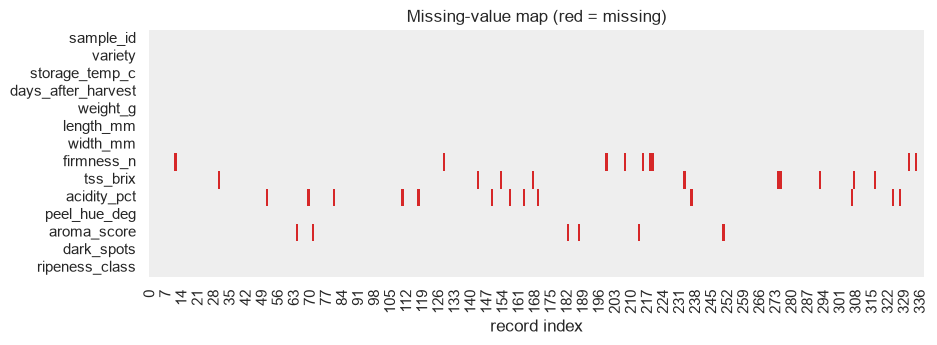

,share_with_missing
ripeness_class,
Overripe,0.104
Ripe,0.135
Unripe,0.099


In [5]:
miss = pd.DataFrame({"missing_count": raw.isna().sum(), "missing_%": (raw.isna().mean() * 100).round(2)})
display(miss[miss.missing_count > 0])
fig, ax = plt.subplots(figsize=(10, 3.2))
sns.heatmap(raw.isna().T, cbar=False, cmap=["#eeeeee", "#d62728"], ax=ax)
ax.set_title("Missing-value map (red = missing)"); ax.set_xlabel("record index")
save("eda_missing_map"); plt.show()
# Are values missing at random with respect to the class?
display(raw.assign(any_missing=raw.isna().any(axis=1)).groupby(TARGET)["any_missing"].mean().round(3).to_frame("share_with_missing"))

**Observations and handling (EDA 2).**
* 38 cells are missing (≈0.8 % of all cells), only in four instrument readings: `acidity_pct` 13 (3.85 %), `tss_brix` 10 (2.96 %), `firmness_n` 9 (2.66 %), `aroma_score` 6 (1.78 %). Identification and administrative columns are complete.
* The missing map shows scattered cells with no block pattern, and the share of rows with a missing value is similar for every class (≈10–13 %), so the data are consistent with **Missing Completely At Random** (e.g. an instrument not available at that moment).
* **Handling decision:** deleting rows would lose ≈11 % of the fruit, so values are **imputed with the median** (robust to the skew of `firmness_n`/`acidity_pct` and to the outliers found below). To avoid data leakage the median is computed **on the training split only** in Phase II (P5) and then applied to all rows. Class-wise imputation was rejected because it would use the label.

### EDA 3 – Duplicate records

In [6]:
dup_mask = raw.duplicated(keep="first")
print("Exact duplicate rows:", dup_mask.sum())
print("Duplicate sample_id values:", raw["sample_id"].duplicated().sum())
display(raw[raw.duplicated(keep=False)].sort_values("sample_id").head(16))
df = raw.drop_duplicates(keep="first").reset_index(drop=True)
print("Shape after removing duplicates:", df.shape)

Exact duplicate rows: 8
Duplicate sample_id values: 8


,sample_id,variety,storage_temp_c,days_after_harvest,weight_g,length_mm,width_mm,firmness_n,tss_brix,acidity_pct,peel_hue_deg,aroma_score,dark_spots,ripeness_class
58,MG059,Sindhri,35.0,1.6,478.1,132.4,86.2,42.18,9.99,1.111,98.0,2.6,0,Unripe
59,MG059,Sindhri,35.0,1.6,478.1,132.4,86.2,42.18,9.99,1.111,98.0,2.6,0,Unripe
61,MG061,Sindhri,29.6,5.8,419.0,132.8,82.5,23.86,11.16,0.854,81.6,4.0,0,Unripe
62,MG061,Sindhri,29.6,5.8,419.0,132.8,82.5,23.86,11.16,0.854,81.6,4.0,0,Unripe
136,MG135,Sindhri,27.6,0.0,410.7,111.5,84.4,55.76,8.72,1.609,108.0,1.3,0,Unripe
137,MG135,Sindhri,27.6,0.0,410.7,111.5,84.4,55.76,8.72,1.609,108.0,1.3,0,Unripe
158,MG156,Anwar Ratol,34.6,3.6,290.5,92.9,79.5,23.60,13.46,0.686,90.1,3.7,0,Ripe
159,MG156,Anwar Ratol,34.6,3.6,290.5,92.9,79.5,23.60,13.46,0.686,90.1,3.7,0,Ripe
191,MG188,Anwar Ratol,32.5,5.8,173.1,96.5,61.2,21.17,16.23,0.674,87.0,4.1,0,Ripe
192,MG188,Anwar Ratol,32.5,5.8,173.1,96.5,61.2,21.17,16.23,0.674,87.0,4.1,0,Ripe


Shape after removing duplicates: (330, 14)


**Observations (EDA 3).** 8 rows are exact copies of another row (same `sample_id` and identical measurements) – the same data sheet was typed twice. They are removed (`keep="first"`), leaving **330 unique mangoes**. Removing them is important: a duplicate in the training set and its copy in the test set would make KNN look better than it is (the nearest neighbour would be the fruit itself), and duplicates give some fruit double weight in the clustering.

### EDA 4 – Outlier detection
Three complementary techniques are used:
1. **IQR rule** (Tukey fences): a value is flagged if it is below Q1 − 1.5·IQR or above Q3 + 1.5·IQR.
2. **Z-score**: |z| > 3 means the value is more than 3 standard deviations from the mean.
3. **Domain validity ranges**: physically possible limits for a mango (e.g. Brix cannot exceed ~30 °Brix, hue must lie in 30–140° for green-to-orange fruit). This separates *impossible* values (errors) from *genuine but extreme* fruit.

In [7]:
VALID = {"weight_g": (80, 900), "length_mm": (60, 180), "width_mm": (40, 120), "firmness_n": (0.5, 90),
         "tss_brix": (4, 30), "acidity_pct": (0.03, 3.0), "peel_hue_deg": (30, 140),
         "aroma_score": (1, 10), "storage_temp_c": (10, 40), "days_after_harvest": (0, 30), "dark_spots": (0, 200)}
rows = []
for c in NUM_COLS:
    s = df[c].dropna(); q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    z = np.abs(stats.zscore(s))
    lo, hi = VALID[c]
    rows.append({"feature": c, "IQR_outliers": int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
                 "zscore_gt3": int((z > 3).sum()), "invalid_domain": int(((s < lo) | (s > hi)).sum()),
                 "min": s.min(), "max": s.max(), "valid_range": f"{lo}–{hi}"})
outlier_tbl = pd.DataFrame(rows).set_index("feature"); display(outlier_tbl)

invalid = pd.concat([df.loc[(df[c] < VALID[c][0]) | (df[c] > VALID[c][1]), ["sample_id", c, TARGET]]
                     .assign(feature=c).rename(columns={c: "value"}) for c in NUM_COLS])
print("Domain-invalid (impossible) readings:"); display(invalid)

,IQR_outliers,zscore_gt3,invalid_domain,min,max,valid_range
feature,,,,,,
storage_temp_c,1,1,0,18.0000,38.0,10–40
days_after_harvest,0,0,0,0.0000,21.0,0–30
weight_g,0,1,1,0.1804,555.2,80–900
length_mm,1,1,1,12.4000,147.8,60–180
width_mm,0,0,0,53.7000,97.2,40–120
firmness_n,1,1,1,0.8000,135.3,0.5–90
tss_brix,1,1,1,7.3900,48.0,4–30
acidity_pct,5,1,1,0.0500,9.5,0.03–3.0
peel_hue_deg,1,1,1,44.9000,290.0,30–140


Domain-invalid (impossible) readings:


,sample_id,value,ripeness_class,feature
17,MG018,0.1804,Ripe,weight_g
256,MG257,12.4000,Ripe,length_mm
88,MG089,135.3000,Ripe,firmness_n
143,MG144,48.0000,Unripe,tss_brix
301,MG302,9.5000,Ripe,acidity_pct
201,MG202,290.0000,Overripe,peel_hue_deg


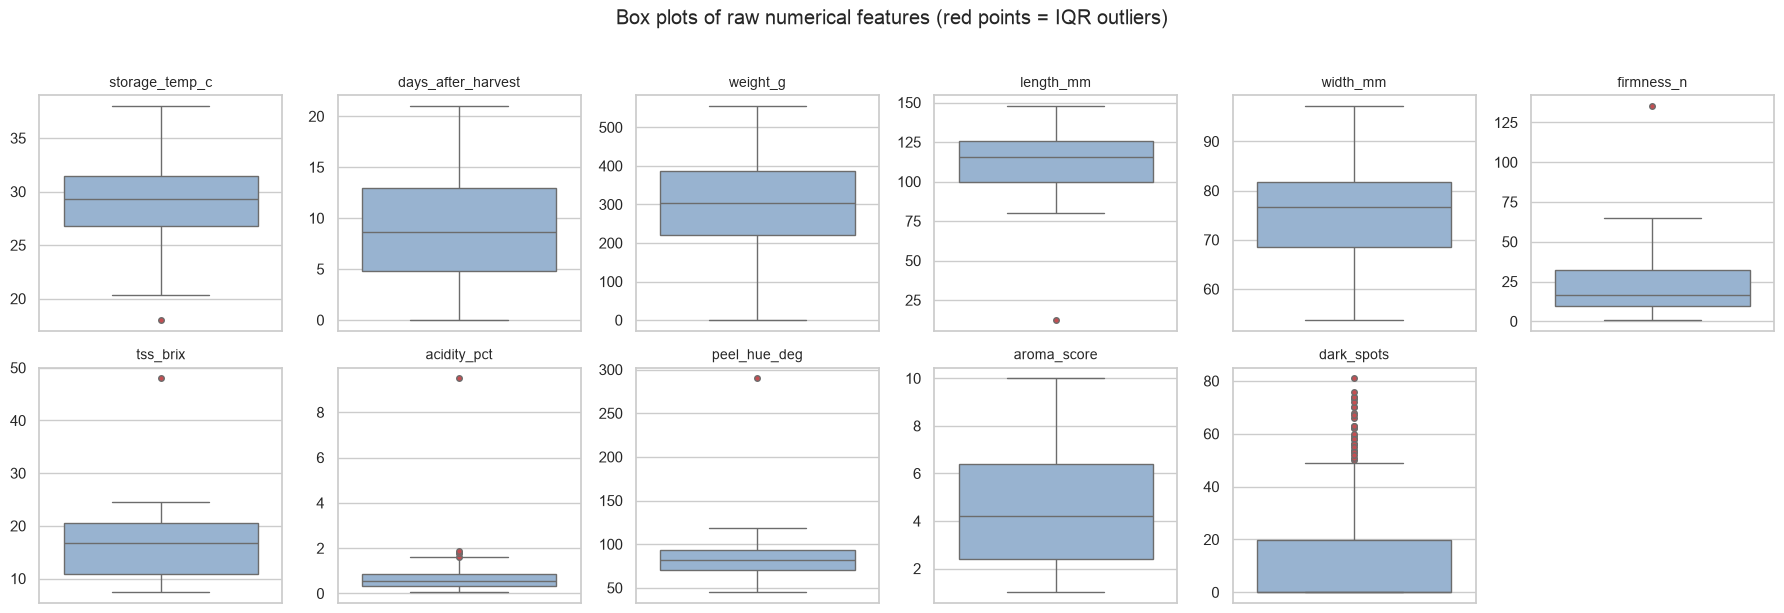

In [8]:
fig, axes = plt.subplots(2, 6, figsize=(18, 6)); axes = axes.ravel()
for ax, c in zip(axes, NUM_COLS):
    sns.boxplot(y=df[c], ax=ax, color="#8fb3d9", flierprops=dict(markerfacecolor="r", markersize=4))
    ax.set_title(c, fontsize=10); ax.set_ylabel("")
axes[-1].axis("off"); fig.suptitle("Box plots of raw numerical features (red points = IQR outliers)", y=1.02)
plt.tight_layout(); save("eda_boxplots_raw"); plt.show()

**Observations (EDA 4).**
* The **domain rule** finds exactly **6 impossible readings**: MG018 weight 0.18 g (typed in kg), MG257 length 12.4 mm (decimal slip), MG089 firmness 135.3 N (extra digit), MG144 Brix 48 (impossible sugar level), MG302 acidity 9.5 % (wrong unit), MG202 hue 290° (colorimeter mis-read). Each is also caught by the z-score rule, confirming they are errors → they are set to missing and imputed in Phase II.
* The **IQR rule** additionally flags 30 high values of `dark_spots` and 5 of `acidity_pct`. These are **not errors**: dark spots only appear on over-ripe fruit (most mangoes have 0, so the IQR is tiny), and high acidity belongs to very green fruit. They are genuine, informative extremes and are **kept**; the right skew of `dark_spots` is handled by a log transform in Phase II.
* `storage_temp_c` has one IQR/z-score flag (38 °C) which is plausible for a hot store in summer – kept.
* Lesson: statistical rules alone would have removed real over-ripe mangoes; combining them with domain limits avoids throwing away class information.

### EDA 5 – Feature distributions (histograms and box plots)
For a clean view of the *natural* distributions, the impossible readings found above are temporarily set to missing (they are treated formally in Phase II).

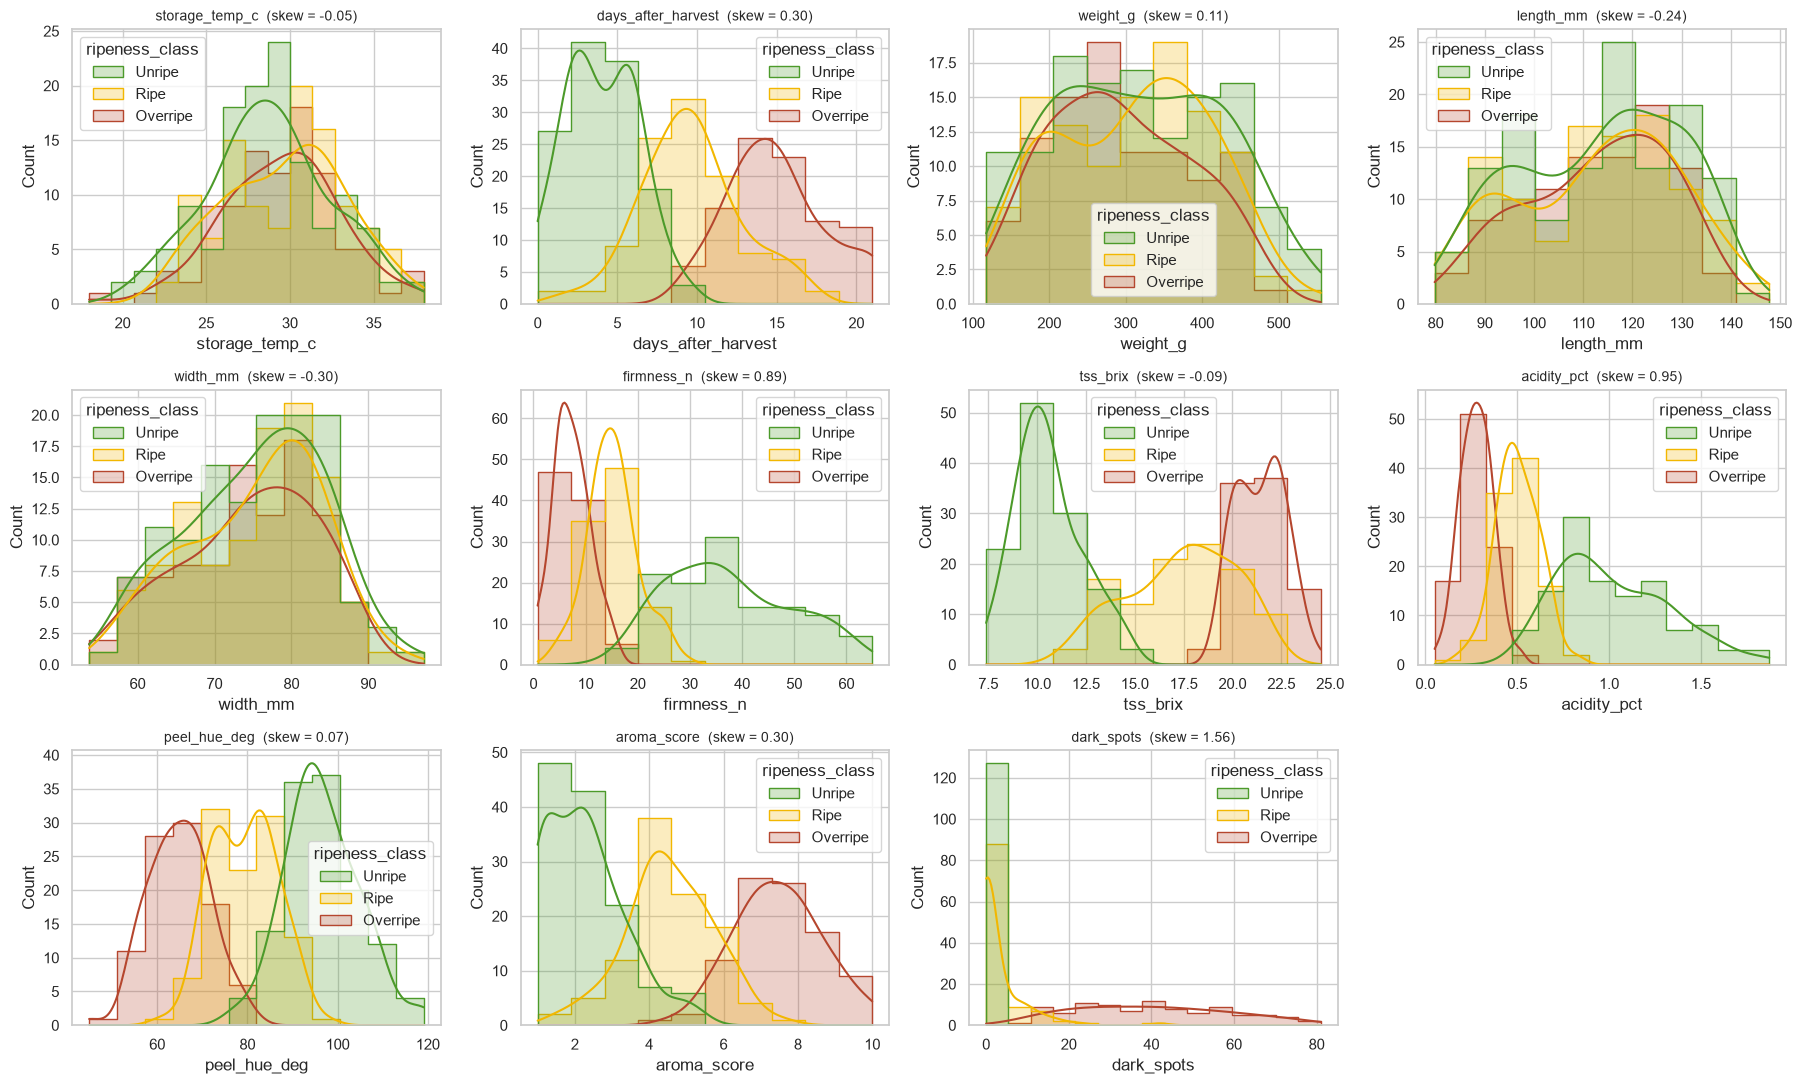

In [9]:
eda = df.copy()
for c, (lo, hi) in VALID.items():
    eda.loc[(eda[c] < lo) | (eda[c] > hi), c] = np.nan
fig, axes = plt.subplots(3, 4, figsize=(18, 11)); axes = axes.ravel()
for ax, c in zip(axes, NUM_COLS):
    sns.histplot(eda, x=c, hue=TARGET, hue_order=CLASS_ORDER, palette=PALETTE, kde=True, element="step", ax=ax)
    ax.set_title(f"{c}  (skew = {eda[c].skew():.2f})", fontsize=10)
axes[-1].axis("off"); plt.tight_layout(); save("eda_histograms"); plt.show()

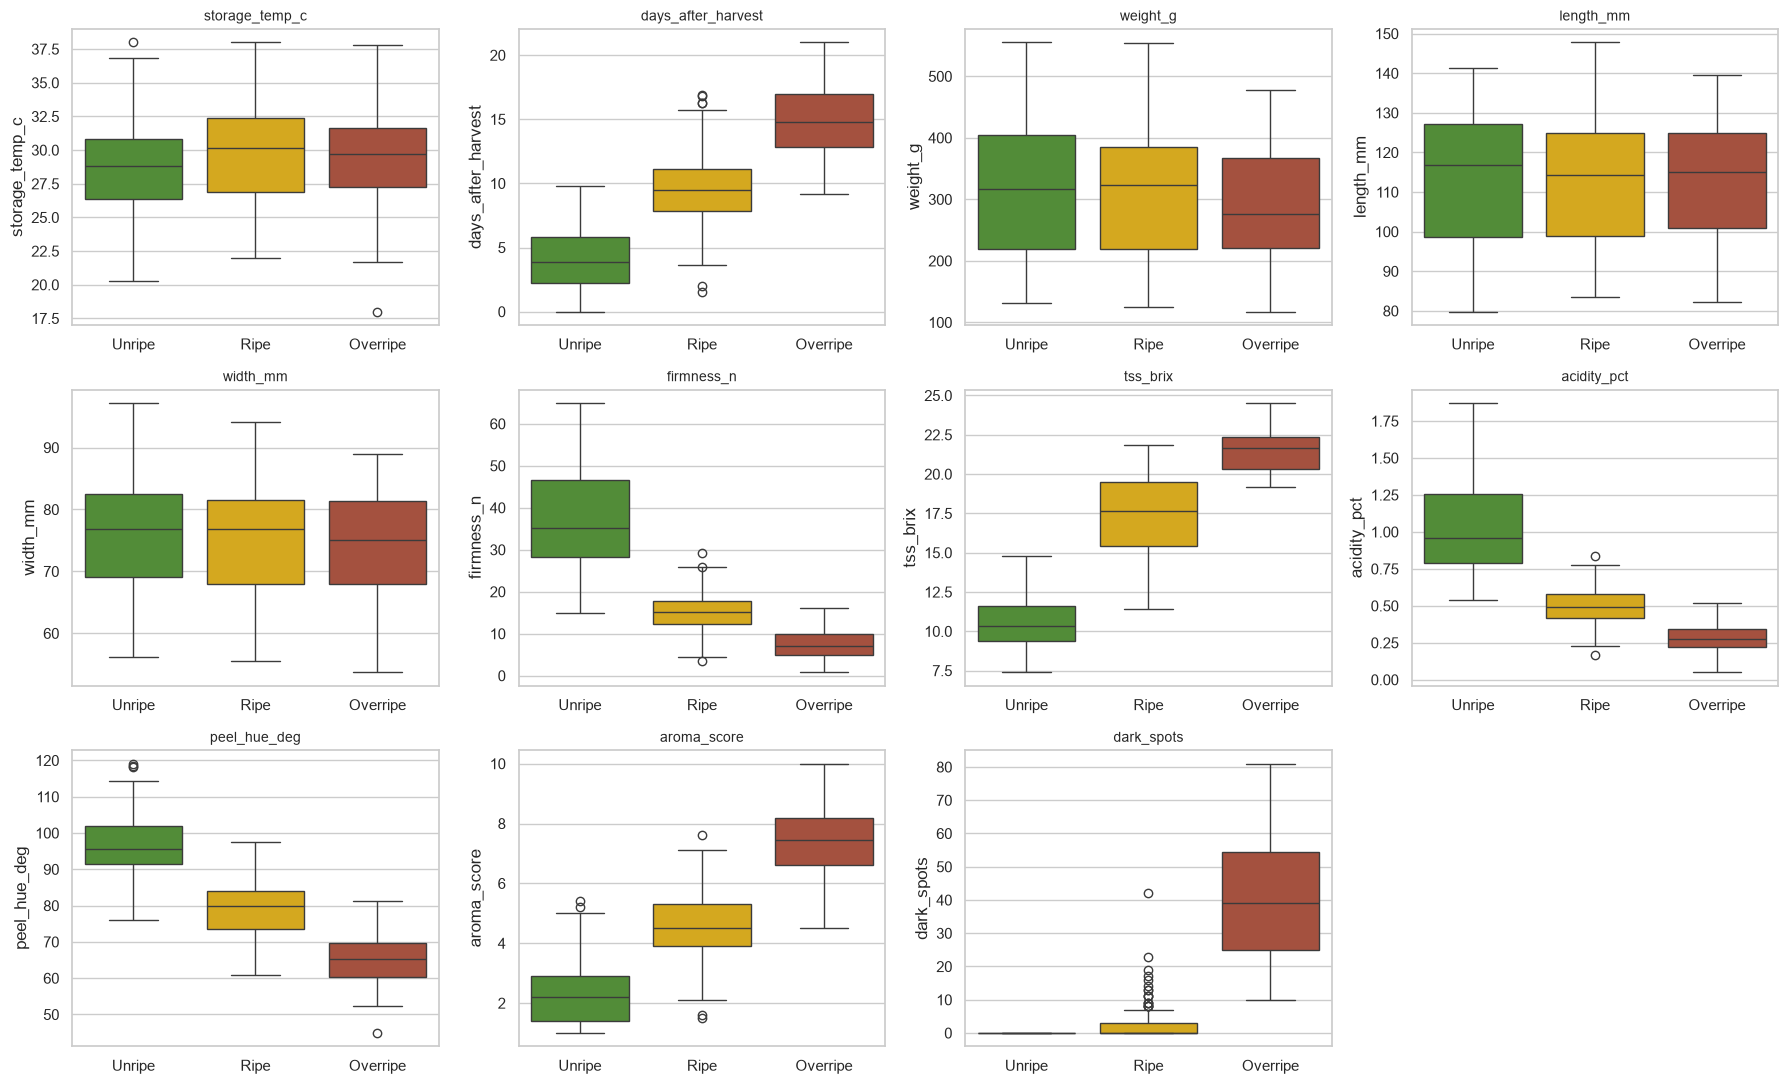

,mean,median,std,skew,kurt
storage_temp_c,29.27,29.35,3.62,-0.05,-0.24
days_after_harvest,9.02,8.60,5.27,0.30,-0.76
weight_g,308.49,304.00,101.02,0.11,-0.95
length_mm,113.17,116.00,15.66,-0.24,-1.00
width_mm,75.09,76.65,8.76,-0.30,-0.68
firmness_n,21.62,16.37,15.36,0.89,-0.14
tss_brix,15.94,16.73,4.93,-0.09,-1.49
acidity_pct,0.63,0.54,0.38,0.95,0.27
peel_hue_deg,81.89,82.40,14.98,0.07,-0.76
aroma_score,4.51,4.20,2.41,0.30,-0.97


In [10]:
fig, axes = plt.subplots(3, 4, figsize=(18, 11)); axes = axes.ravel()
for ax, c in zip(axes, NUM_COLS):
    sns.boxplot(eda, x=TARGET, y=c, order=CLASS_ORDER, palette=PALETTE, hue=TARGET, legend=False, ax=ax)
    ax.set_title(c, fontsize=10); ax.set_xlabel("")
axes[-1].axis("off"); plt.tight_layout(); save("eda_boxplots_by_class"); plt.show()
display(eda[NUM_COLS].agg(["mean", "median", "std", "skew", "kurt"]).T.round(2))

**Observations (EDA 5).**
* **Strong ripening signals:** `firmness_n`, `tss_brix`, `acidity_pct`, `peel_hue_deg`, `aroma_score`, `days_after_harvest` and `dark_spots` have clearly shifted distributions per class. Firmness falls from a median of 35 N (Unripe) to 15 N (Ripe) to 7 N (Overripe); Brix rises 10.4 → 17.6 → 21.6; hue drops 96° → 80° → 65°.
* **Shapes:** `firmness_n` (skew 0.89) and `acidity_pct` (0.95) are right-skewed (exponential decay during ripening); `dark_spots` is strongly skewed (1.56) with a spike at 0; `tss_brix` is bimodal with negative kurtosis (−1.49) because sugar follows a sigmoid with a fast transition. Size variables (`weight_g`, `length_mm`, `width_mm`) are multimodal because the three varieties have different sizes.
* **Weak/no signal:** size attributes and `storage_temp_c` have almost identical box plots for all classes – they describe the fruit/environment rather than its ripeness.
* **Overlap:** the Ripe box overlaps the Unripe box on the lower side and the Overripe box on the upper side for every attribute, because ripening is continuous. This already suggests that most classification errors will involve the *Ripe* class.

### EDA 6 – Relationships between numerical features (correlation analysis)

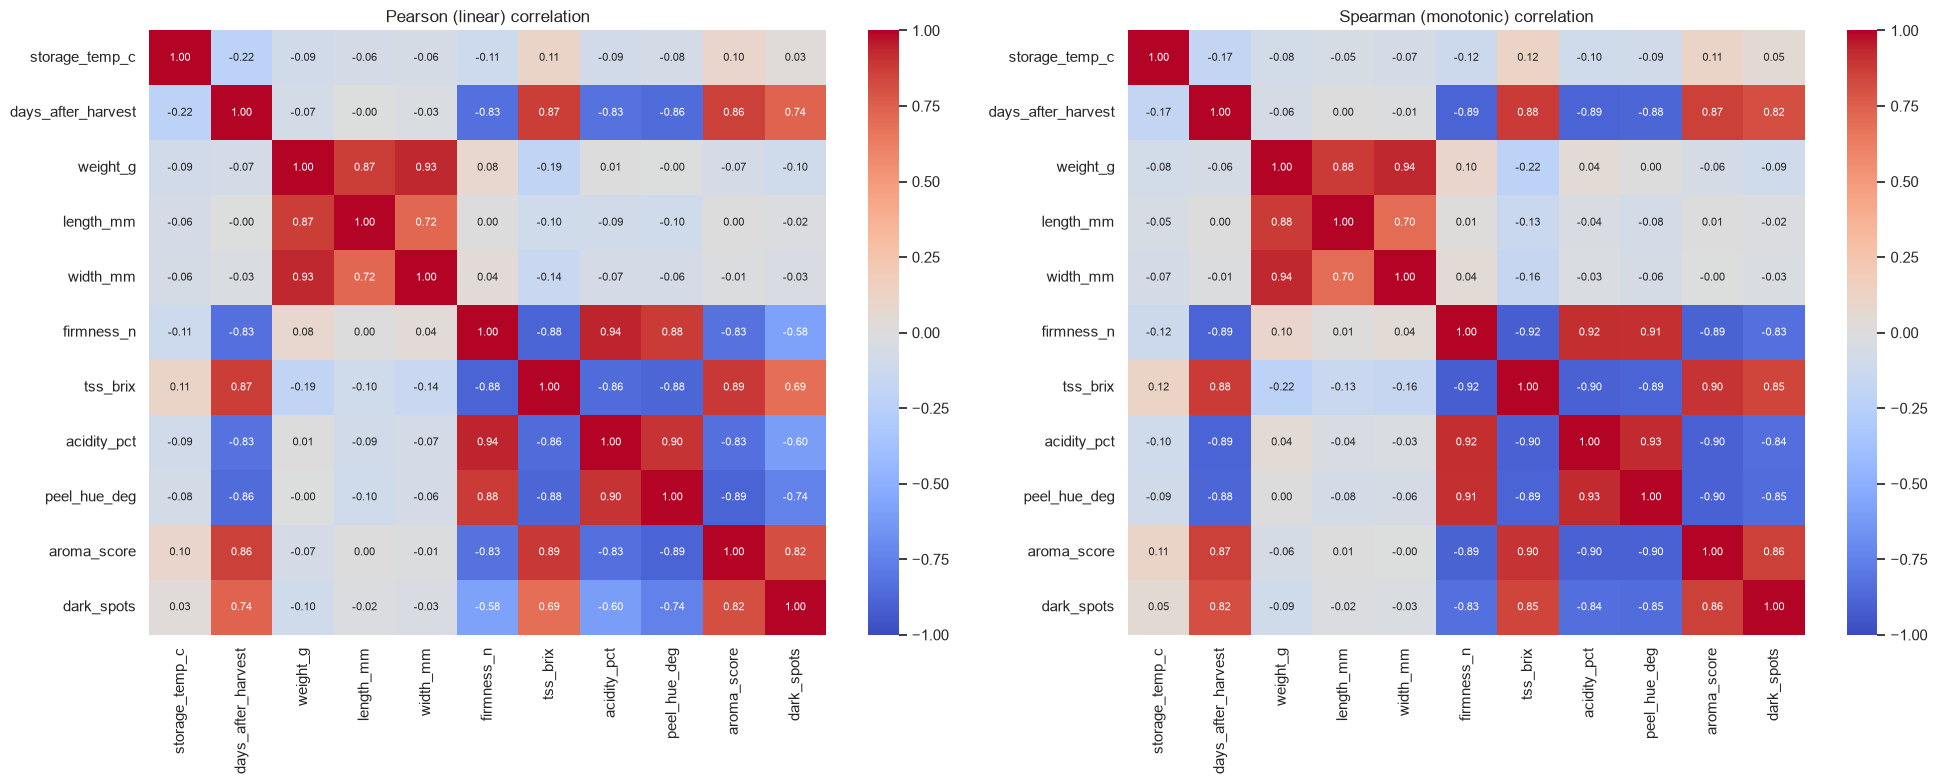

Strongest feature pairs (Pearson):


r
firmness_n         acidity_pct   0.939
weight_g           width_mm      0.933
acidity_pct        peel_hue_deg  0.899
tss_brix           aroma_score   0.890
peel_hue_deg       aroma_score  -0.887
firmness_n         tss_brix     -0.883
                   peel_hue_deg  0.880
tss_brix           peel_hue_deg -0.880
days_after_harvest tss_brix      0.870
weight_g           length_mm     0.869

In [11]:
corr = eda[NUM_COLS].corr(method="pearson")
spear = eda[NUM_COLS].corr(method="spearman")
fig, axes = plt.subplots(1, 2, figsize=(20, 8))
for ax, m, t in [(axes[0], corr, "Pearson (linear)"), (axes[1], spear, "Spearman (monotonic)")]:
    sns.heatmap(m, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, annot_kws={"size": 8})
    ax.set_title(f"{t} correlation")
plt.tight_layout(); save("eda_correlation"); plt.show()
pairs = corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().sort_values(key=abs, ascending=False)
print("Strongest feature pairs (Pearson):"); display(pairs.head(10).round(3).to_frame("r"))

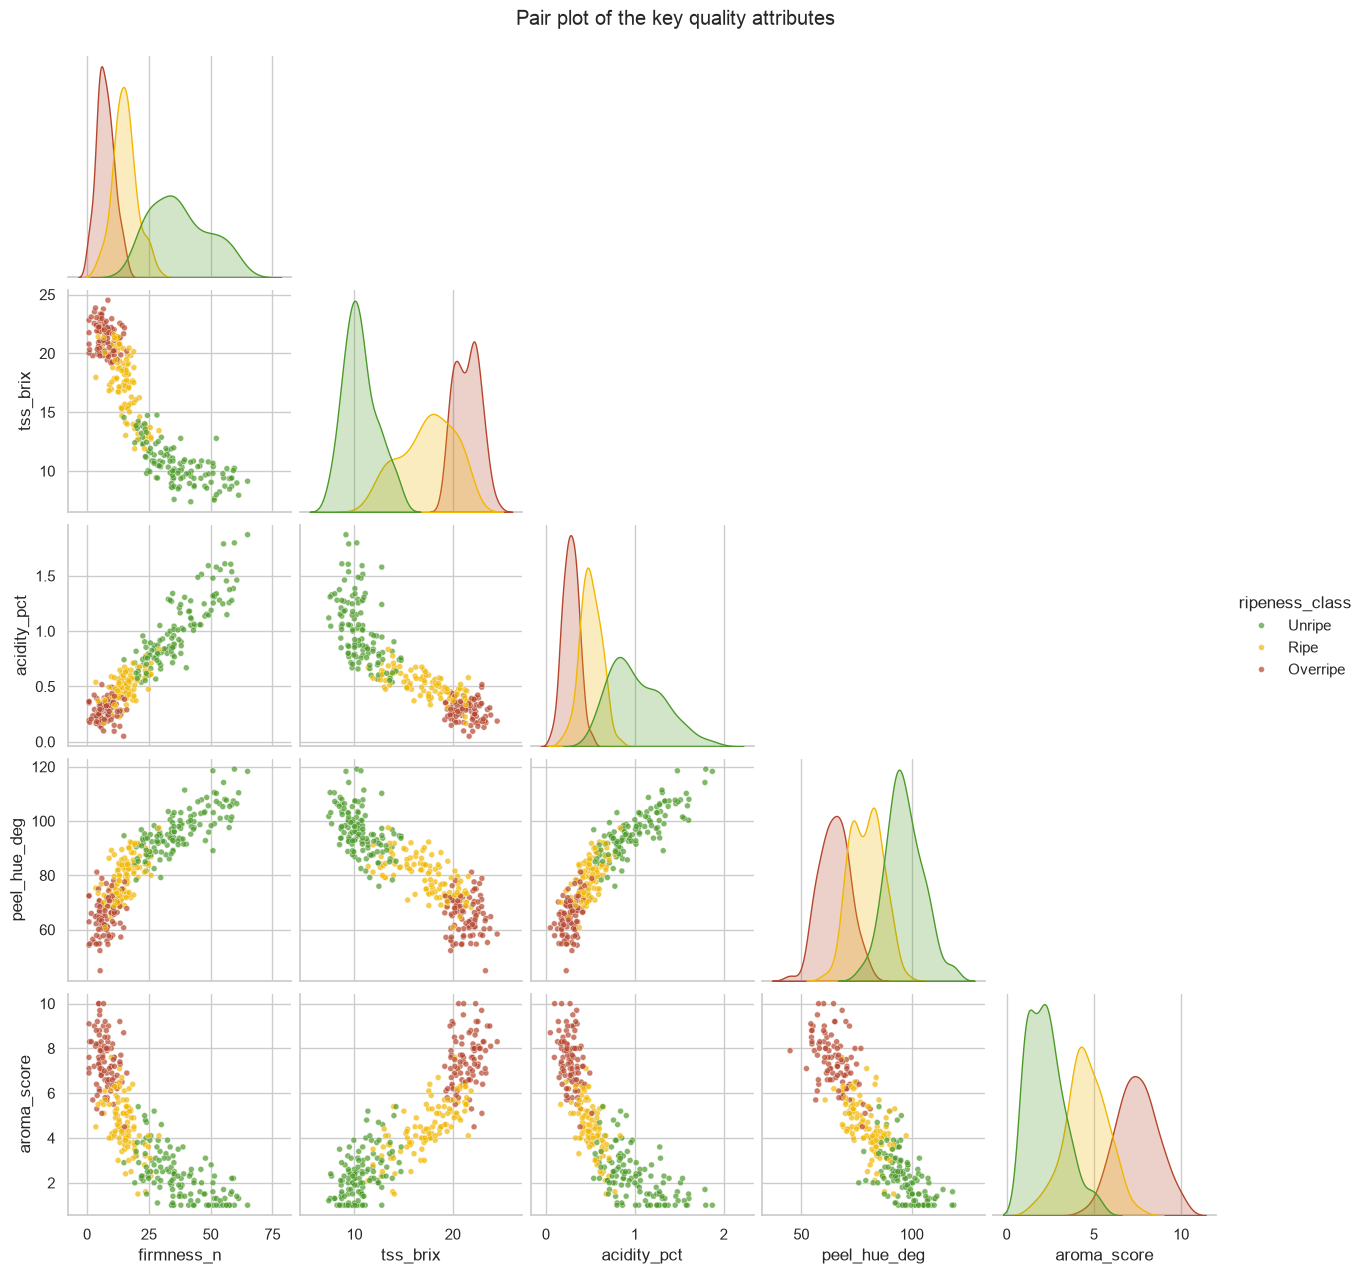

In [12]:
g = sns.pairplot(eda, vars=["firmness_n", "tss_brix", "acidity_pct", "peel_hue_deg", "aroma_score"],
                 hue=TARGET, hue_order=CLASS_ORDER, palette=PALETTE, corner=True, plot_kws=dict(s=18, alpha=.7))
g.figure.suptitle("Pair plot of the key quality attributes", y=1.02); save("eda_pairplot"); plt.show()

**Observations (EDA 6).**
* The ripeness attributes form one **highly correlated block**: firmness–acidity r = 0.94, acidity–hue 0.90, Brix–aroma 0.89, hue–aroma −0.89, firmness–Brix −0.88, days–Brix 0.87. Physiologically they are all driven by the same hidden ripening process, so they carry partly **redundant** information. This motivates the redundancy check in feature selection and PCA for visualisation (PC1 alone explains ≈84 % of the variance of the selected features).
* A second, independent block is **size**: weight–width 0.93, weight–length 0.87. Size is almost uncorrelated with the ripeness block.
* `storage_temp_c` is nearly uncorrelated with everything; its effect only appears in combination with time (motivating the engineered `thermal_time` feature).
* Spearman and Pearson matrices are similar, but Spearman is higher for monotonic non-linear pairs (e.g. firmness–Brix), confirming curved relationships visible in the pair plot.
* The pair plot shows that Unripe and Overripe are well separated in every 2-D projection, while Ripe sits between them with overlapping edges.

### EDA 7 – Distribution and balance of class labels

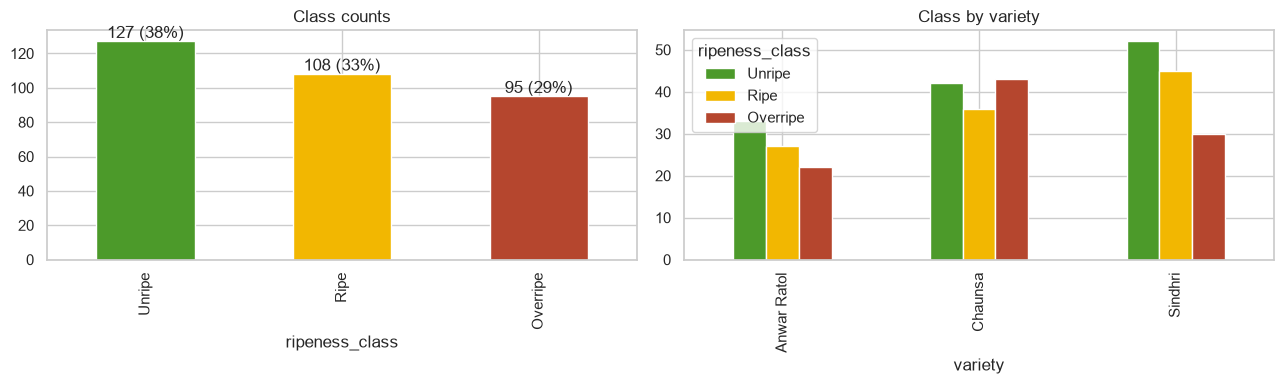

Imbalance ratio (largest / smallest class): 1.34


ripeness_class,Unripe,Ripe,Overripe,All
variety,,,,
Anwar Ratol,33,27,22,82
Chaunsa,42,36,43,121
Sindhri,52,45,30,127
All,127,108,95,330


In [13]:
cnt = df[TARGET].value_counts().reindex(CLASS_ORDER)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cnt.plot.bar(ax=axes[0], color=[PALETTE[c] for c in CLASS_ORDER]); axes[0].set_title("Class counts")
for i, v in enumerate(cnt): axes[0].text(i, v + 2, f"{v} ({v / cnt.sum():.0%})", ha="center")
pd.crosstab(df["variety"], df[TARGET])[CLASS_ORDER].plot.bar(ax=axes[1], color=[PALETTE[c] for c in CLASS_ORDER])
axes[1].set_title("Class by variety"); plt.tight_layout(); save("eda_class_balance"); plt.show()
print("Imbalance ratio (largest / smallest class): %.2f" % (cnt.max() / cnt.min()))
display(pd.crosstab(df["variety"], df[TARGET], margins=True)[CLASS_ORDER + ["All"]])

**Observations (EDA 7).** After de-duplication: Unripe 127 (38 %), Ripe 108 (33 %), Overripe 95 (29 %). The imbalance ratio is **1.34**, i.e. mildly imbalanced – no resampling is needed, but (i) a **stratified** train/test split and stratified CV folds are used so every split keeps these proportions, and (ii) **macro-averaged** precision/recall/F1 are reported alongside accuracy so the smallest class counts equally. All three classes occur in all three varieties, so variety cannot be a shortcut for the label.

### EDA 8 – Representative samples from the collected dataset
For tabular data a "sample" is a record, so I show (a) three real records per class, (b) the class *profile* (median of each attribute) and (c) a standardised profile plot that visualises how a typical mango of each class looks across all attributes.

,sample_id,variety,storage_temp_c,days_after_harvest,weight_g,length_mm,width_mm,firmness_n,tss_brix,acidity_pct,peel_hue_deg,aroma_score,dark_spots,ripeness_class
248,MG249,Sindhri,29.4,15.4,423.5,122.5,87.3,13.43,21.34,0.286,62.4,7.3,32,Overripe
94,MG095,Anwar Ratol,28.0,16.5,180.7,95.7,61.6,0.80,21.76,0.357,62.9,7.1,66,Overripe
257,MG258,Chaunsa,33.7,11.2,266.0,116.6,73.1,5.89,23.30,0.186,63.3,7.1,52,Overripe
193,MG194,Sindhri,32.9,10.0,406.2,118.4,83.3,10.02,17.57,0.409,73.1,4.2,1,Ripe
41,MG042,Sindhri,32.0,10.0,403.5,136.2,78.9,12.57,18.69,0.431,71.8,4.4,0,Ripe
317,MG318,Anwar Ratol,32.5,6.8,177.6,93.4,63.5,17.02,20.45,0.428,73.7,6.2,1,Ripe
66,MG067,Anwar Ratol,29.7,6.4,227.8,98.4,65.9,19.86,13.84,0.818,90.5,3.2,0,Unripe
35,MG036,Chaunsa,23.9,7.4,334.4,115.7,77.2,34.79,9.33,0.871,88.8,3.2,0,Unripe
202,MG203,Chaunsa,29.9,5.6,295.4,112.3,75.3,NaN,12.49,0.776,76.0,2.0,0,Unripe


,storage_temp_c,days_after_harvest,weight_g,length_mm,width_mm,firmness_n,tss_brix,acidity_pct,peel_hue_deg,aroma_score,dark_spots
ripeness_class,,,,,,,,,,,
Unripe,28.80,3.9,316.0,116.8,76.9,35.18,10.36,0.96,95.70,2.20,0.0
Ripe,30.15,9.5,323.6,114.2,76.9,15.19,17.62,0.49,79.80,4.50,0.0
Overripe,29.70,14.8,276.8,115.1,75.0,7.09,21.64,0.28,65.15,7.45,39.0


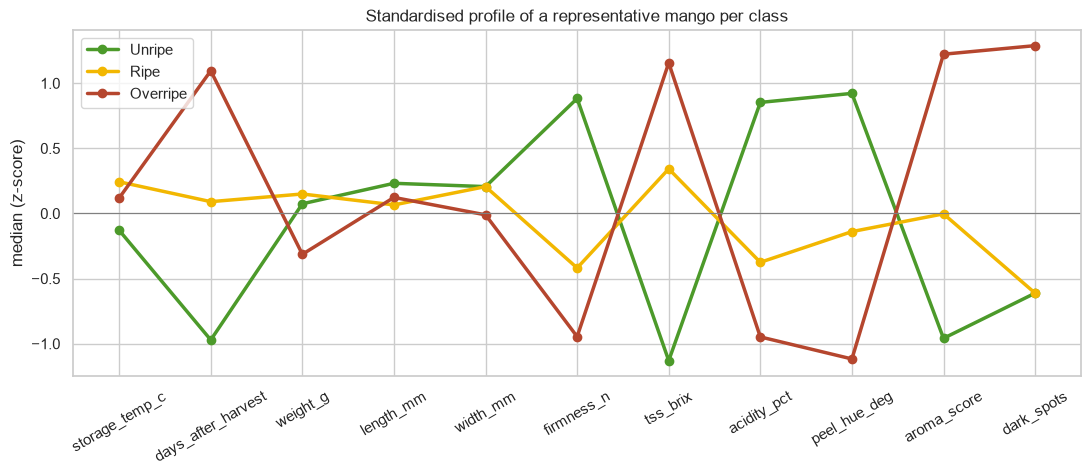

In [14]:
display(df.groupby(TARGET).sample(3, random_state=SEED).loc[:, ["sample_id", "variety"] + NUM_COLS + [TARGET]])
profile = eda.groupby(TARGET)[NUM_COLS].median().loc[CLASS_ORDER]
display(profile.round(2))
z_profile = (profile - eda[NUM_COLS].mean()) / eda[NUM_COLS].std()
fig, ax = plt.subplots(figsize=(13, 4.5))
for cl in CLASS_ORDER:
    ax.plot(NUM_COLS, z_profile.loc[cl], marker="o", lw=2.5, color=PALETTE[cl], label=cl)
ax.axhline(0, color="grey", lw=.8); ax.set_ylabel("median (z-score)"); ax.legend()
ax.set_title("Standardised profile of a representative mango per class"); plt.xticks(rotation=30)
save("eda_class_profiles"); plt.show()

**Observations (EDA 8).** The representative records and the profile plot show the typical mango of each class:
* **Unripe** – firm (≈35 N), sour (acidity ≈0.96 %), low sugar (≈10 °Brix), green peel (hue ≈96°), weak aroma, no spots, ≈4 days after harvest.
* **Ripe** – medium firmness (≈15 N), ≈17.6 °Brix, yellow peel (≈80°), moderate aroma, usually no spots, ≈9.5 days.
* **Overripe** – soft (≈7 N), very sweet (≈21.6 °Brix), low acid, orange peel (≈65°), strong aroma and many dark spots (median 39), ≈15 days.
The profile lines are almost parallel and ordered Unripe → Ripe → Overripe for every ripeness attribute, while the size and temperature attributes are flat – a visual summary of which features matter.

### Additional tabular EDA – statistical tests of class separation

In [15]:
rows = []
for c in NUM_COLS:
    groups = [eda.loc[eda[TARGET] == k, c].dropna() for k in CLASS_ORDER]
    F, pF = stats.f_oneway(*groups); H, pH = stats.kruskal(*groups)
    rows.append({"feature": c, "ANOVA_F": F, "ANOVA_p": pF, "Kruskal_H": H, "Kruskal_p": pH})
tests = pd.DataFrame(rows).set_index("feature").sort_values("ANOVA_F", ascending=False)
display(tests.style.format({"ANOVA_F": "{:.1f}", "Kruskal_H": "{:.1f}", "ANOVA_p": "{:.2e}", "Kruskal_p": "{:.2e}"}))

,ANOVA_F,ANOVA_p,Kruskal_H,Kruskal_p
feature,,,,
tss_brix,808.1,3.48e-125,257.5,1.20e-56
aroma_score,579.6,2.88e-107,251.8,2.08e-55
peel_hue_deg,492.8,2.81e-99,256.9,1.62e-56
dark_spots,471.2,4.89e-97,265.0,2.82e-58
days_after_harvest,415.2,1.75e-90,243.5,1.32e-53
firmness_n,414.8,3.15e-89,256.2,2.33e-56
acidity_pct,378.1,3.22e-84,256.5,1.95e-56
storage_temp_c,2.4,9.35e-02,5.1,7.65e-02
weight_g,1.7,1.89e-01,2.9,2.29e-01


**Observations (statistical tests).** One-way ANOVA and the non-parametric Kruskal–Wallis test (which does not assume normality – important for the skewed features) agree: `tss_brix`, `aroma_score`, `peel_hue_deg`, `dark_spots`, `days_after_harvest`, `firmness_n` and `acidity_pct` differ between classes with p-values below 10⁻⁵⁰, whereas `weight_g` (p ≈ 0.19), `length_mm` (p ≈ 0.98), `width_mm` (p ≈ 0.75) and `storage_temp_c` (p ≈ 0.09) are **not** significant at α = 0.05. This statistical evidence is used again in feature selection.

## 3. Phase II – Data Preprocessing and Feature Engineering  *(Deliverable 4)*

### A. Preprocessing plan (operation, reason, parameters)

| # | Operation | Why it is necessary | Parameters |
|---|---|---|---|
| P1 | Remove exact duplicates | Double-entered rows give some fruit double weight, bias distances and could leak between train and test sets | `drop_duplicates(keep="first")` (done in EDA 3) |
| P2 | Treat impossible readings as missing | Values outside physical limits are data-entry errors, not real fruit; keeping them would distort scaling and distances | domain validity ranges from EDA 4 |
| P3 | Keep genuine extreme values | High dark-spot counts and very soft fruit are real over-ripe mangoes and carry class information | — |
| P4 | Stratified train/test split **before** any fitted step | Prevents information leakage from test data into imputation, feature selection or scaling | 75 % / 25 %, `stratify=y`, `random_state=42` |
| P5 | Median imputation (fit on training data only) | KNN, K-Means and Agglomerative cannot handle NaN; median is robust to skew/outliers; missingness is small (≤4 %) and not class-related | `SimpleImputer(strategy="median")` |
| P6 | One-hot encode `variety` | Algorithms need numbers; one-hot avoids a fake order between cultivars | 3 binary columns |
| P7 | Feature engineering | Ratios/aggregates capture ripening physiology better than raw readings (see B) | formulas below |
| P8 | Feature selection | Remove features with no class information (they add noise to distance-based methods – *curse of dimensionality*) and near-duplicates | mutual information + ANOVA F on training set, redundancy |r| > 0.95 |
| P9 | Standardisation | KNN and clustering use distances; without scaling, `weight_g` (hundreds) would dominate `acidity_pct` (≈0.1–1.7) | `StandardScaler` (z = (x−μ)/σ), fit on training data only |

In [16]:
# P2 – impossible readings -> NaN
clean = df.copy()
n_fixed = 0
for c, (lo, hi) in VALID.items():
    bad = (clean[c] < lo) | (clean[c] > hi); n_fixed += bad.sum(); clean.loc[bad, c] = np.nan
print("Impossible readings converted to missing:", n_fixed)
print("Missing values now:", int(clean[NUM_COLS].isna().sum().sum()))

# P4 – stratified split on the de-duplicated data (indices reused by every later phase)
y_all = clean[TARGET]
idx_train, idx_test = train_test_split(clean.index, test_size=0.25, stratify=y_all, random_state=SEED)
print("Train:", len(idx_train), "| Test:", len(idx_test))
display(pd.DataFrame({"train": y_all[idx_train].value_counts(normalize=True), "test": y_all[idx_test].value_counts(normalize=True)}).loc[CLASS_ORDER].round(3))

# P5 – median imputer fitted on TRAINING rows only, then applied to all rows
imputer = SimpleImputer(strategy="median").fit(clean.loc[idx_train, NUM_COLS])
clean[NUM_COLS] = imputer.transform(clean[NUM_COLS])
display(pd.Series(imputer.statistics_, index=NUM_COLS, name="training median used").round(3).to_frame())
print("Remaining missing values:", int(clean.isna().sum().sum()))

Impossible readings converted to missing: 6
Missing values now: 43
Train: 247 | Test: 83


,train,test
ripeness_class,,
Unripe,0.385,0.386
Ripe,0.328,0.325
Overripe,0.287,0.289


,training median used
storage_temp_c,29.600
days_after_harvest,8.400
weight_g,301.650
length_mm,116.550
width_mm,76.300
firmness_n,16.570
tss_brix,16.495
acidity_pct,0.538
peel_hue_deg,82.150
aroma_score,4.400


Remaining missing values: 0


### B. Feature extraction / engineering

| New feature | Formula | What it represents | Why it should separate the classes |
|---|---|---|---|
| `brix_acid_ratio` | tss_brix / acidity_pct | **Sugar–acid ratio**, the classic maturity index used by the fruit industry | Sugar rises and acid falls during ripening, so the ratio grows multiplicatively (≈10 → ≈80) |
| `sweet_soft_index` | tss_brix / firmness_n | Sweetness per unit of firmness | Combines the two strongest ripening signals; explodes for soft, sweet over-ripe fruit |
| `firmness_per_100g` | firmness_n / (weight_g / 100) | Size-normalised firmness | Removes the effect that large fruit may need more force |
| `thermal_time` | days_after_harvest × (storage_temp_c − 10) | **Accumulated degree-days** above a 10 °C base (aggregated feature) | Ripening is driven by heat accumulated over time, not days alone |
| `volume_cm3` | π/6 · length · width² / 1000 | Ellipsoid volume estimate | Size descriptor; needed for density |
| `density_g_cm3` | weight_g / volume_cm3 | Apparent density | Moisture loss during ripening lowers density slightly |
| `log_dark_spots` | ln(1 + dark_spots) | Log-scaled spot count | Removes the strong right skew (many zeros, few large counts) |
| `variety_*` | one-hot | Cultivar | Varieties differ in sugar and colour baselines |

Candidate features: 21


,brix_acid_ratio,sweet_soft_index,firmness_per_100g,thermal_time,volume_cm3,density_g_cm3,log_dark_spots
ripeness_class,,,,,,,
Unripe,12.08,0.34,13.25,73.84,350.51,0.91,0.00
Ripe,37.78,1.33,5.58,182.55,346.86,0.90,0.72
Overripe,88.17,4.46,2.84,282.87,339.88,0.87,3.60


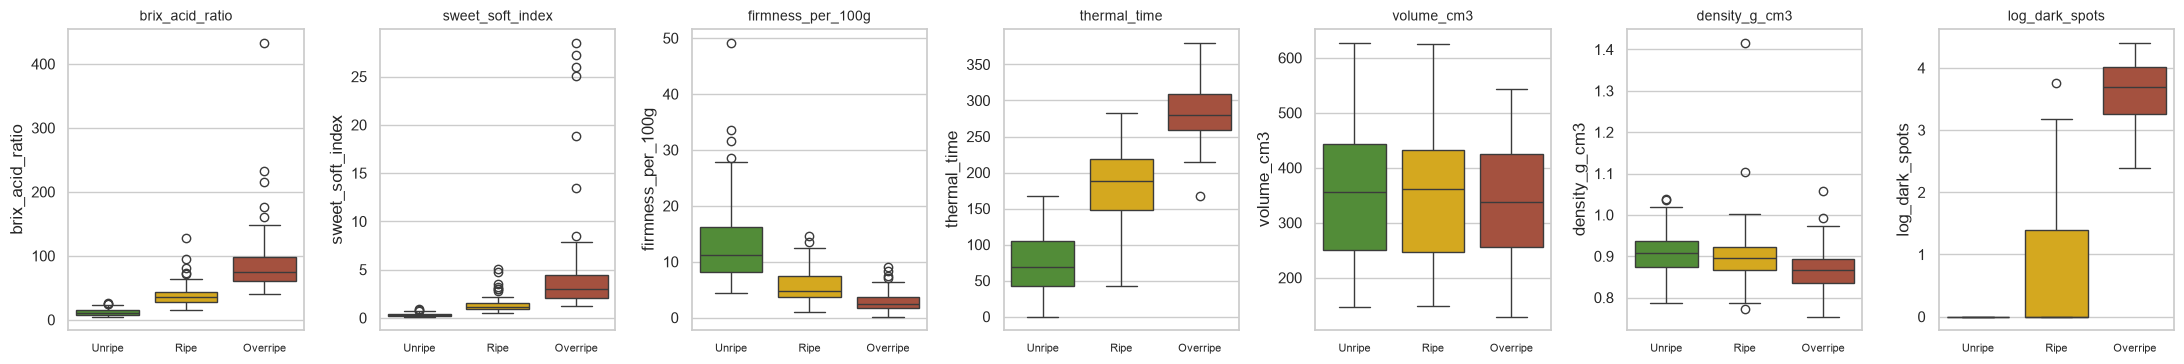

In [17]:
def engineer(d):
    d = d.copy()
    d["brix_acid_ratio"] = d["tss_brix"] / d["acidity_pct"]
    d["sweet_soft_index"] = d["tss_brix"] / d["firmness_n"]
    d["firmness_per_100g"] = d["firmness_n"] / (d["weight_g"] / 100)
    d["thermal_time"] = d["days_after_harvest"] * (d["storage_temp_c"] - 10)
    d["volume_cm3"] = np.pi / 6 * d["length_mm"] * d["width_mm"] ** 2 / 1000
    d["density_g_cm3"] = d["weight_g"] / d["volume_cm3"]
    d["log_dark_spots"] = np.log1p(d["dark_spots"])
    return pd.concat([d, pd.get_dummies(d["variety"], prefix="variety", dtype=int)], axis=1)

feat = engineer(clean)
ENG = ["brix_acid_ratio", "sweet_soft_index", "firmness_per_100g", "thermal_time", "volume_cm3", "density_g_cm3", "log_dark_spots"]
VAR = [c for c in feat if c.startswith("variety_")]
CANDIDATES = NUM_COLS + ENG + VAR
print("Candidate features:", len(CANDIDATES))
display(feat.groupby(TARGET)[ENG].mean().loc[CLASS_ORDER].round(2))

fig, axes = plt.subplots(1, 7, figsize=(22, 3.8))
for ax, c in zip(axes, ENG):
    sns.boxplot(feat, x=TARGET, y=c, order=CLASS_ORDER, palette=PALETTE, hue=TARGET, legend=False, ax=ax)
    ax.set_title(c, fontsize=10); ax.set_xlabel(""); ax.tick_params(axis="x", labelsize=8)
plt.tight_layout(); save("fe_engineered_boxplots"); plt.show()

### C. Feature selection (fitted on the training set only)
* **Mutual information (MI)** measures how much knowing a feature reduces uncertainty about the class (captures non-linear relations; 0 = independent).
* **ANOVA F** measures between-class variance relative to within-class variance (linear separation of class means).
* Rule: keep features with MI ≥ 0.10 **and** ANOVA p < 0.05 (both a non-linear and a linear test must agree the feature carries class information), then remove one member of any pair with Spearman |ρ| > 0.95 (redundant/monotonic copies double-count one direction in distance-based methods); the member with the lower ANOVA F is dropped.

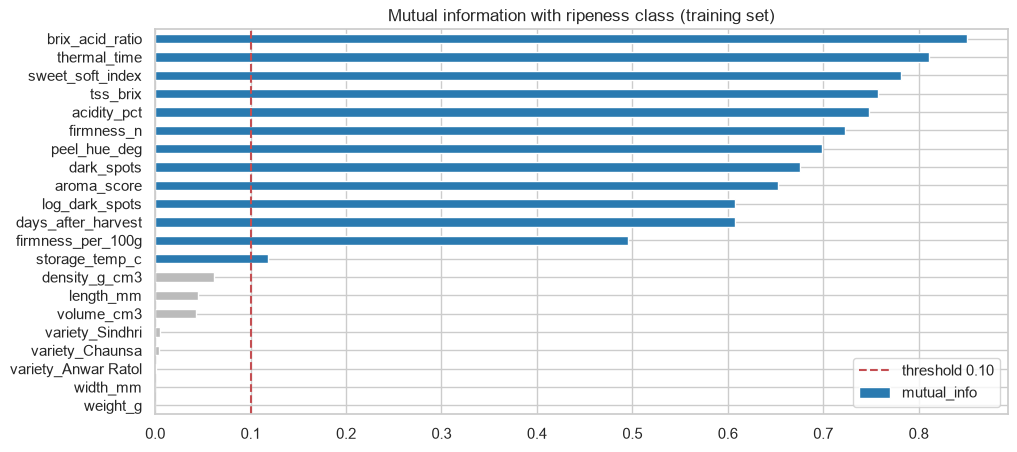

,mutual_info,ANOVA_F,p_value,selected
brix_acid_ratio,0.8507,130.7592,0.0000,False
thermal_time,0.8103,537.5758,0.0000,True
sweet_soft_index,0.7816,49.1967,0.0000,False
tss_brix,0.7572,577.4738,0.0000,True
acidity_pct,0.7481,237.4459,0.0000,True
firmness_n,0.7228,276.4036,0.0000,True
peel_hue_deg,0.6988,362.9953,0.0000,True
dark_spots,0.6752,342.2734,0.0000,False
aroma_score,0.6524,408.9589,0.0000,True
log_dark_spots,0.6080,626.9041,0.0000,True


Redundant pairs (Spearman |rho| > 0.95): [('brix_acid_ratio', 'acidity_pct', np.float64(0.985)), ('sweet_soft_index', 'firmness_n', np.float64(0.993)), ('dark_spots', 'log_dark_spots', np.float64(1.0))]
Dropped for redundancy: ['brix_acid_ratio', 'sweet_soft_index', 'dark_spots']
FINAL SELECTED FEATURES (9): ['thermal_time', 'tss_brix', 'acidity_pct', 'firmness_n', 'peel_hue_deg', 'aroma_score', 'log_dark_spots', 'days_after_harvest', 'firmness_per_100g']


In [18]:
Xc_tr = feat.loc[idx_train, CANDIDATES]; y_tr = feat.loc[idx_train, TARGET]
mi = mutual_info_classif(Xc_tr, y_tr, discrete_features=[c in VAR or c == "dark_spots" for c in CANDIDATES], random_state=SEED)
F, pF = f_classif(Xc_tr, y_tr)
sel_tbl = pd.DataFrame({"mutual_info": mi, "ANOVA_F": F, "p_value": pF}, index=CANDIDATES).sort_values("mutual_info", ascending=False)

fig, ax = plt.subplots(figsize=(11, 5))
sel_tbl["mutual_info"].plot.barh(ax=ax, color=["#2a7ab0" if v >= 0.10 else "#bbbbbb" for v in sel_tbl["mutual_info"]])
ax.axvline(0.10, color="r", ls="--", label="threshold 0.10"); ax.invert_yaxis(); ax.legend()
ax.set_title("Mutual information with ripeness class (training set)"); save("fe_mutual_info"); plt.show()

keep = sel_tbl.index[(sel_tbl["mutual_info"] >= 0.10) & (sel_tbl["p_value"] < 0.05)].tolist()
# redundancy filter: drop the lower-ANOVA-F member of highly (monotonically) correlated pairs
cm = feat.loc[idx_train, keep].corr(method="spearman").abs(); dropped = []; red_pairs = []
for i, a in enumerate(keep):
    for b in keep[i + 1:]:
        if a not in dropped and b not in dropped and cm.loc[a, b] > 0.95:
            red_pairs.append((a, b, round(cm.loc[a, b], 3)))
            dropped.append(b if sel_tbl.loc[a, "ANOVA_F"] >= sel_tbl.loc[b, "ANOVA_F"] else a)
SELECTED = [c for c in keep if c not in dropped]
sel_tbl["selected"] = sel_tbl.index.isin(SELECTED)
display(sel_tbl.round(4))
print("Redundant pairs (Spearman |rho| > 0.95):", red_pairs)
print("Dropped for redundancy:", dropped)
print(f"FINAL SELECTED FEATURES ({len(SELECTED)}):", SELECTED)
RESULTS["selected_features"] = SELECTED

**Explanation of the selected features.**
* **Removed – no class information:** `weight_g`, `length_mm`, `width_mm`, `volume_cm3`, `density_g_cm3` and the three `variety_*` columns have MI < 0.10 (size and cultivar do not determine ripeness). `storage_temp_c` passes the MI threshold (0.118) only by chance – its ANOVA p-value is 0.39, so it is dropped. Keeping such features would add pure noise dimensions to every distance computation.
* **Removed – redundancy (Spearman |ρ| > 0.95):** `brix_acid_ratio` vs `acidity_pct` (ρ = 0.985), `sweet_soft_index` vs `firmness_n` (ρ = 0.993) and `dark_spots` vs `log_dark_spots` (ρ = 1.0, a monotonic transform). In each pair the member with the higher ANOVA F (better linear separation of class means) was kept. Because the ratios are almost monotonic functions of one of their components, they rank the fruit the same way and would double-count that direction. They remain useful for interpretation (e.g. the sugar–acid ratio rises 12 → 38 → 88 across classes).
* **Final set (9 features):** `thermal_time`, `tss_brix`, `acidity_pct`, `firmness_n`, `peel_hue_deg`, `aroma_score`, `log_dark_spots`, `days_after_harvest`, `firmness_per_100g`. Three of them are engineered (`thermal_time`, `log_dark_spots`, `firmness_per_100g`). Together they describe four complementary aspects of ripening: **texture** (firmness, size-normalised firmness), **chemistry** (sugar, acid), **appearance/aroma** (hue, spots, aroma) and **time/heat history** (days, degree-days). Each one moves monotonically with ripeness, which is exactly what a distance-based method needs to separate the classes.
* The KNN ablation in Phase III shows that this selected representation gives a higher cross-validated accuracy than both the raw attributes and the full set of 21 candidates.

In [19]:
# Final numerical feature dataset (one row per mango) – saved as a deliverable
final = feat[["sample_id"] + SELECTED + [TARGET]].copy()
final.insert(1, "split", np.where(final.index.isin(idx_train), "train", "test"))
final.to_csv("data/mango_features.csv", index=False)
feat[["sample_id"] + CANDIDATES + [TARGET]].to_csv("data/mango_features_all_candidates.csv", index=False)
print("Saved data/mango_features.csv", final.shape)
final.head(8).round(3)

Saved data/mango_features.csv (330, 12)


,sample_id,split,thermal_time,tss_brix,acidity_pct,firmness_n,peel_hue_deg,aroma_score,log_dark_spots,days_after_harvest,firmness_per_100g,ripeness_class
0,MG001,train,127.36,11.37,0.840,27.16,90.1,5.2,0.000,6.4,13.033,Unripe
1,MG002,train,332.93,20.79,0.289,6.34,65.4,7.7,3.829,16.9,1.379,Overripe
2,MG003,test,314.64,22.82,0.193,0.80,72.6,7.6,3.555,15.2,0.387,Overripe
3,MG004,test,303.36,22.59,0.170,5.13,66.5,7.3,3.401,15.8,1.580,Overripe
4,MG005,test,168.72,16.96,0.588,9.86,89.2,4.0,0.000,7.4,1.999,Ripe
5,MG006,train,171.72,17.96,0.538,3.57,75.3,4.5,1.792,8.1,0.961,Ripe
6,MG007,train,199.02,18.19,0.564,16.38,77.6,4.7,0.000,10.7,3.552,Ripe
7,MG008,test,103.04,11.21,0.862,33.27,86.1,2.5,0.000,5.6,11.773,Unripe


## 4. Phase III – KNN Classification  *(Deliverable 5)*

### How KNN works
K-Nearest Neighbors is a **lazy, instance-based** supervised learner. `fit()` only stores the (scaled) training points. To classify a new mango it:
1. computes the distance from the new point to **every** training point,
2. takes the **K** closest ones,
3. predicts the class by **majority vote** (`weights="uniform"`) or a vote weighted by 1/distance (`weights="distance"`).

Key parameters explored:
* `n_neighbors` (K): small K → flexible boundary, low bias / high variance (sensitive to noise); large K → smoother boundary, higher bias. Odd values avoid ties between two classes.
* `metric`: **Euclidean** $d=\sqrt{\sum_j (x_j-y_j)^2}$ (straight-line, penalises large single differences); **Manhattan** $d=\sum_j |x_j-y_j|$ (city-block, more robust to one noisy feature); **Chebyshev** $d=\max_j|x_j-y_j|$ (only the largest difference counts).
* `weights`: uniform vs distance-weighted voting.

Scaling is essential because KNN is distance-based. The scaler is placed **inside a `Pipeline`**, so during cross-validation it is re-fitted on the training folds only, and for the final model it is fitted on the training set only and merely applied to the test set.

**Model-selection protocol:** configurations are compared with **5-fold stratified cross-validation on the training set**; the test set is used only once to report the final performance of the chosen model (test scores of all configurations are also shown for transparency, but not used for selection).

In [20]:
X_tr = feat.loc[idx_train, SELECTED].values; X_te = feat.loc[idx_test, SELECTED].values
y_tr = feat.loc[idx_train, TARGET].values;  y_te = feat.loc[idx_test, TARGET].values
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

K_VALUES = [1, 3, 5, 7, 9, 11, 15, 21]
rows = []
for metric in ["euclidean", "manhattan", "chebyshev"]:
    for weights in ["uniform", "distance"]:
        for k in K_VALUES:
            pipe = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=k, metric=metric, weights=weights))])
            cvs = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="accuracy")
            cvf = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="f1_macro")
            pipe.fit(X_tr, y_tr); pred = pipe.predict(X_te)
            rows.append({"metric": metric, "weights": weights, "K": k, "cv_acc_mean": cvs.mean(), "cv_acc_std": cvs.std(),
                         "cv_f1_macro": cvf.mean(), "train_acc": pipe.score(X_tr, y_tr), "test_acc": accuracy_score(y_te, pred),
                         "test_f1_macro": precision_recall_fscore_support(y_te, pred, average="macro")[2]})
grid = pd.DataFrame(rows)
display(grid.pivot_table(index="K", columns=["metric", "weights"], values="cv_acc_mean").round(3))

metric  chebyshev         euclidean         manhattan        
weights  distance uniform  distance uniform  distance uniform
K                                                            
1           0.867   0.867     0.867   0.867     0.883   0.883
3           0.907   0.903     0.919   0.919     0.931   0.931
5           0.895   0.891     0.911   0.903     0.903   0.899
7           0.907   0.911     0.899   0.899     0.907   0.899
9           0.895   0.899     0.903   0.899     0.899   0.895
11          0.895   0.907     0.899   0.895     0.899   0.895
15          0.915   0.915     0.899   0.903     0.911   0.911
21          0.907   0.903     0.907   0.911     0.907   0.907

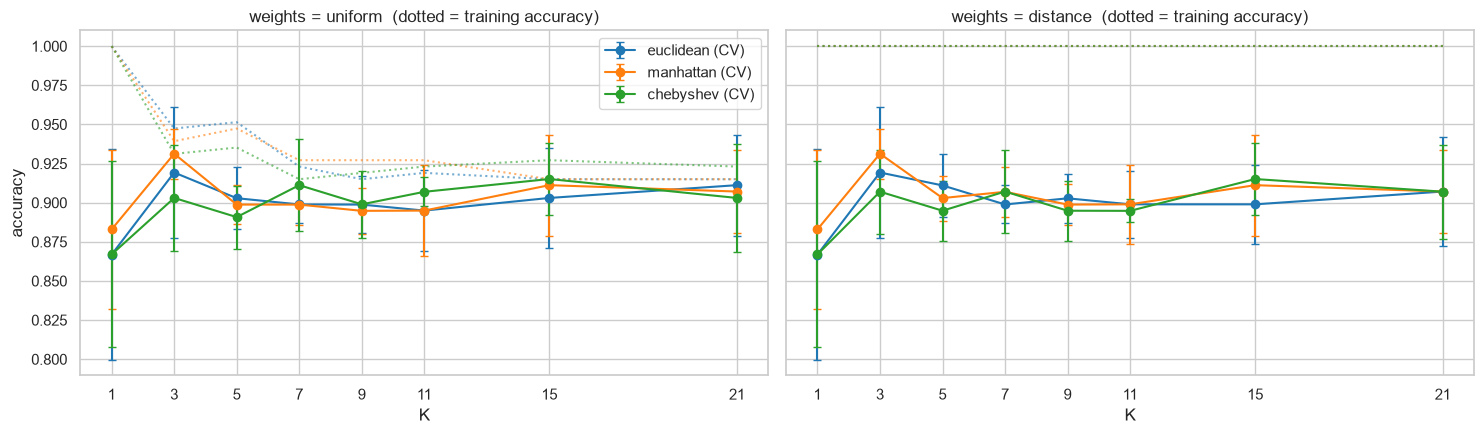

Top-10 configurations by cross-validated accuracy:


,metric,weights,K,cv_acc_mean,cv_acc_std,cv_f1_macro,train_acc,test_acc,test_f1_macro
17,manhattan,uniform,3,0.9313,0.0158,0.9318,0.9393,0.8795,0.8764
25,manhattan,distance,3,0.9313,0.0158,0.9318,1.0000,0.8795,0.8764
1,euclidean,uniform,3,0.9193,0.0417,0.9195,0.9474,0.8916,0.8905
9,euclidean,distance,3,0.9193,0.0417,0.9195,1.0000,0.8916,0.8905
38,chebyshev,uniform,15,0.9151,0.0233,0.9127,0.9271,0.9277,0.9296
46,chebyshev,distance,15,0.9151,0.0233,0.9127,1.0000,0.9277,0.9296
35,chebyshev,uniform,7,0.9112,0.0294,0.9097,0.9150,0.9036,0.9027
22,manhattan,uniform,15,0.9112,0.0322,0.9085,0.9150,0.9036,0.9014
30,manhattan,distance,15,0.9112,0.0322,0.9085,1.0000,0.9036,0.9014
7,euclidean,uniform,21,0.9112,0.0322,0.9079,0.9150,0.9036,0.9014


BEST CONFIGURATION: {'metric': 'manhattan', 'weights': 'uniform', 'K': np.int64(3)}


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, w in zip(axes, ["uniform", "distance"]):
    for m, col in zip(["euclidean", "manhattan", "chebyshev"], ["#1f77b4", "#ff7f0e", "#2ca02c"]):
        g = grid[(grid.metric == m) & (grid.weights == w)]
        ax.errorbar(g.K, g.cv_acc_mean, yerr=g.cv_acc_std, marker="o", capsize=3, color=col, label=f"{m} (CV)")
        ax.plot(g.K, g.train_acc, ls=":", color=col, alpha=.6)
    ax.set_title(f"weights = {w}  (dotted = training accuracy)"); ax.set_xlabel("K"); ax.set_xticks(K_VALUES)
axes[0].set_ylabel("accuracy"); axes[0].legend(); plt.tight_layout(); save("knn_k_vs_accuracy"); plt.show()

# Best = highest CV accuracy; ties broken by higher CV macro-F1, then lower CV std, then larger K (simpler boundary)
best = grid.sort_values(["cv_acc_mean", "cv_f1_macro", "cv_acc_std", "K"], ascending=[False, False, True, False]).iloc[0]
print("Top-10 configurations by cross-validated accuracy:")
display(grid.sort_values(["cv_acc_mean", "cv_f1_macro"], ascending=False).head(10).round(4))
print("BEST CONFIGURATION:", dict(best[["metric", "weights", "K"]]))

In [22]:
# Required comparison: K = 1,3,5,7,9 with Euclidean vs Manhattan (uniform voting)
req = grid[(grid.K.isin([1, 3, 5, 7, 9])) & (grid.metric.isin(["euclidean", "manhattan"])) & (grid.weights == "uniform")]
display(req.pivot_table(index="K", columns="metric", values=["cv_acc_mean", "test_acc", "test_f1_macro"]).round(3))

cv_acc_mean            test_acc           test_f1_macro          
metric   euclidean manhattan euclidean manhattan     euclidean manhattan
K                                                                       
1            0.867     0.883     0.892     0.892         0.888     0.889
3            0.919     0.931     0.892     0.880         0.890     0.876
5            0.903     0.899     0.892     0.904         0.890     0.905
7            0.899     0.899     0.916     0.916         0.917     0.915
9            0.899     0.895     0.916     0.916         0.917     0.915

In [23]:
# Does feature engineering + selection help? Same CV protocol, best metric/K found above, three representations.
def cv_rep(cols):
    p = Pipeline([("scaler", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=int(best.K), metric=best.metric, weights=best.weights))])
    sc_ = cross_val_score(p, feat.loc[idx_train, cols].values, y_tr, cv=cv, scoring="accuracy"); return sc_.mean(), sc_.std()
abl = pd.DataFrame({name: cv_rep(cols) for name, cols in [("raw 11 numeric attributes", NUM_COLS), ("all 21 candidates (raw + engineered + one-hot)", CANDIDATES),
                                                         (f"selected {len(SELECTED)} features", SELECTED)]}, index=["cv_acc_mean", "cv_acc_std"]).T
display(abl.round(4)); RESULTS["ablation"] = abl.round(4).to_dict(orient="index")

,cv_acc_mean,cv_acc_std
raw 11 numeric attributes,0.9029,0.0293
all 21 candidates (raw + engineered + one-hot),0.8869,0.0366
selected 9 features,0.9313,0.0158


**Comparison and choice of the best configuration.**
* **Effect of K:** K = 1 gives the lowest CV accuracy (0.867–0.883) and 100 % training accuracy – classic over-fitting to individual noisy fruit near the class boundaries. Accuracy peaks at **K = 3** for Euclidean and Manhattan and then slowly declines/plateaus (≈0.90) as larger neighbourhoods start to include fruit from the neighbouring ripeness stage.
* **Effect of the metric:** Manhattan ≥ Euclidean for most K and Chebyshev is the weakest for small K. With 9 standardised features, Manhattan sums the absolute differences, so a single noisy measurement (e.g. one odd aroma score) cannot dominate the distance as it does when differences are squared (Euclidean) or when only the maximum difference counts (Chebyshev).
* **Effect of weighting:** distance weighting changes the results very little, because with K = 3 the vote is rarely tied; it always gives 100 % training accuracy (each training point is its own neighbour with infinite weight).
* **Selected model: K = 3, Manhattan distance, uniform voting** – highest mean CV accuracy (**0.931**) and CV macro-F1 (**0.932**) with a low standard deviation across folds (0.016) and a training accuracy (0.939) close to the CV accuracy (no strong over-fitting). The distance-weighted variant ties exactly, so the simpler uniform vote is preferred.
* **Representation ablation:** with the same K/metric, the 9 selected features (CV 0.931) beat the 11 raw attributes (0.903) and all 21 candidates (0.887) – adding uninformative size/variety dimensions *hurts* KNN, which confirms the feature-selection step.
* Note on the test column: some configurations score higher on the 83-mango test set (e.g. Chebyshev K = 15 → 0.928), but choosing on test results would be optimistic “test-set tuning”. Differences of 1–4 test mangoes are within the sampling noise of a small test set, so selection is based on CV only.

### Final model evaluation on the held-out test set

Test accuracy = 0.8795

              precision    recall  f1-score   support

      Unripe     0.8824    0.9375    0.9091        32
        Ripe     0.8696    0.7407    0.8000        27
    Overripe     0.8846    0.9583    0.9200        24

    accuracy                         0.8795        83
   macro avg     0.8788    0.8789    0.8764        83
weighted avg     0.8788    0.8795    0.8768        83



,precision,recall,f1,support
Unripe,0.8824,0.9375,0.9091,32
Ripe,0.8696,0.7407,0.8000,27
Overripe,0.8846,0.9583,0.9200,24
macro avg,0.8788,0.8789,0.8764,83
weighted avg,0.8788,0.8795,0.8768,83


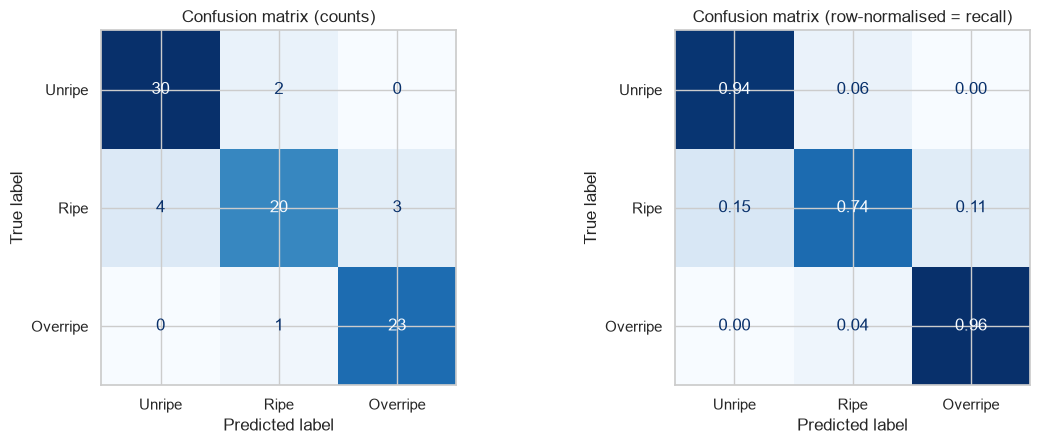

In [24]:
best_knn = Pipeline([("scaler", StandardScaler()),
                     ("knn", KNeighborsClassifier(n_neighbors=int(best.K), metric=best.metric, weights=best.weights))]).fit(X_tr, y_tr)
y_pred = best_knn.predict(X_te)
acc = accuracy_score(y_te, y_pred)
p, r, f, s = precision_recall_fscore_support(y_te, y_pred, labels=CLASS_ORDER)
pm, rm, fm, _ = precision_recall_fscore_support(y_te, y_pred, average="macro")
pw, rw, fw, _ = precision_recall_fscore_support(y_te, y_pred, average="weighted")
print(f"Test accuracy = {acc:.4f}\n")
print(classification_report(y_te, y_pred, labels=CLASS_ORDER, digits=4))
metrics_tbl = pd.DataFrame({"precision": p, "recall": r, "f1": f, "support": s}, index=CLASS_ORDER)
metrics_tbl.loc["macro avg"] = [pm, rm, fm, s.sum()]; metrics_tbl.loc["weighted avg"] = [pw, rw, fw, s.sum()]
display(metrics_tbl.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred, labels=CLASS_ORDER), display_labels=CLASS_ORDER).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred, labels=CLASS_ORDER, normalize="true"), display_labels=CLASS_ORDER).plot(ax=axes[1], cmap="Blues", colorbar=False, values_format=".2f")
axes[1].set_title("Confusion matrix (row-normalised = recall)")
plt.tight_layout(); save("knn_confusion_matrix"); plt.show()

RESULTS["knn"] = {"metric": best.metric, "weights": best.weights, "K": int(best.K), "cv_acc": float(best.cv_acc_mean),
                  "test_acc": float(acc), "macro_precision": float(pm), "macro_recall": float(rm), "macro_f1": float(fm),
                  "per_class": metrics_tbl.round(4).to_dict(orient="index")}

### Analysis of incorrectly classified observations

In [25]:
test_df = feat.loc[idx_test, ["sample_id", "variety"] + SELECTED + [TARGET]].copy()
test_df["predicted"] = y_pred
test_df["P(" + pd.Index(best_knn.classes_) + ")"] = best_knn.predict_proba(X_te).round(2)
wrong = test_df[test_df[TARGET] != test_df["predicted"]]
print(f"Misclassified: {len(wrong)} of {len(test_df)} test mangoes")
display(wrong.round(3))

# Where do the errors sit relative to the class profiles?
cols_show = ["firmness_n", "tss_brix", "acidity_pct", "peel_hue_deg", "aroma_score"]
cols_show = [c for c in cols_show if c in SELECTED] or SELECTED[:5]
print("Class means on the training set, for comparison:")
display(feat.loc[idx_train].groupby(TARGET)[cols_show].mean().loc[CLASS_ORDER].round(2))

# Distance of each test point's neighbours: misclassified points live in mixed neighbourhoods
sc = best_knn.named_steps["scaler"]; knn = best_knn.named_steps["knn"]
dist, ind = knn.kneighbors(sc.transform(X_te))
test_df["neighbour_purity"] = [(y_tr[i] == yt).mean() for i, yt in zip(ind, y_te)]
display(test_df.groupby(test_df[TARGET] == test_df["predicted"])["neighbour_purity"].describe().rename(index={True: "correct", False: "wrong"}).round(3))

Misclassified: 10 of 83 test mangoes


,sample_id,variety,thermal_time,tss_brix,acidity_pct,firmness_n,peel_hue_deg,aroma_score,log_dark_spots,days_after_harvest,firmness_per_100g,ripeness_class,predicted,P(Overripe),P(Ripe),P(Unripe)
328,MG329,Chaunsa,224.37,21.33,0.333,11.13,68.9,6.3,2.639,8.1,3.896,Ripe,Overripe,0.67,0.33,0.00
322,MG323,Chaunsa,167.25,13.86,0.622,19.84,78.3,3.4,0.000,7.5,5.967,Unripe,Ripe,0.00,0.67,0.33
217,MG218,Anwar Ratol,138.61,13.44,0.835,29.12,97.5,4.1,0.000,8.3,14.670,Ripe,Unripe,0.00,0.00,1.00
86,MG087,Anwar Ratol,127.80,13.90,0.776,23.68,87.7,1.6,0.000,6.0,11.534,Ripe,Unripe,0.00,0.33,0.67
304,MG305,Anwar Ratol,248.00,22.17,0.384,15.16,77.6,4.5,2.398,16.0,8.257,Overripe,Ripe,0.33,0.67,0.00
78,MG079,Sindhri,52.20,11.90,0.538,19.29,91.2,3.5,0.000,2.0,5.103,Ripe,Unripe,0.00,0.00,1.00
325,MG326,Sindhri,226.27,21.42,0.460,12.37,70.0,5.8,2.197,12.1,3.627,Ripe,Overripe,0.67,0.33,0.00
155,MG156,Anwar Ratol,88.56,13.46,0.686,23.60,90.1,3.7,0.000,3.6,8.124,Ripe,Unripe,0.00,0.33,0.67
80,MG081,Sindhri,152.64,11.57,0.662,25.81,87.5,4.1,0.000,7.2,5.676,Unripe,Ripe,0.00,0.67,0.33
112,MG113,Anwar Ratol,250.58,21.87,0.381,7.18,68.2,6.1,2.079,13.4,4.094,Ripe,Overripe,1.00,0.00,0.00


Class means on the training set, for comparison:


,firmness_n,tss_brix,acidity_pct,peel_hue_deg,aroma_score
ripeness_class,,,,,
Unripe,36.76,10.75,0.99,96.80,2.32
Ripe,15.42,17.42,0.50,79.04,4.57
Overripe,7.26,21.33,0.28,65.74,7.50


,count,mean,std,min,25%,50%,75%,max
wrong,10.0,0.233,0.161,0.000,0.083,0.333,0.333,0.333
correct,73.0,0.973,0.092,0.667,1.000,1.000,1.000,1.000


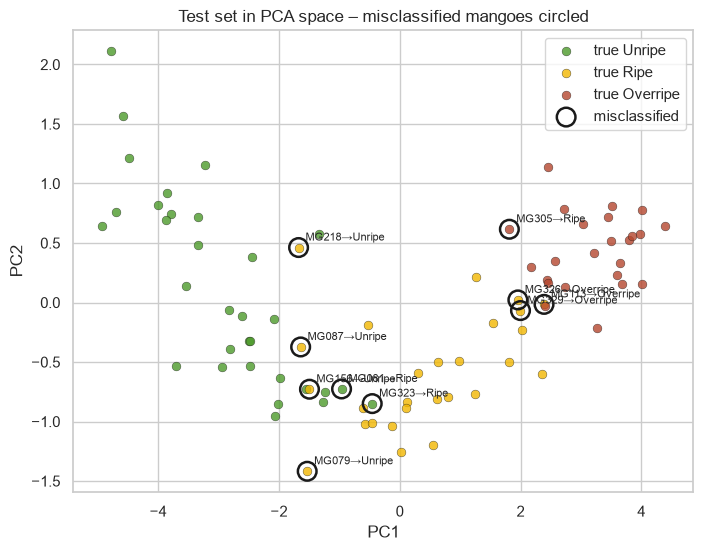

In [26]:
pca_vis = PCA(n_components=2, random_state=SEED).fit(sc.transform(X_tr))
Z_te = pca_vis.transform(sc.transform(X_te))
fig, ax = plt.subplots(figsize=(8, 6))
for cl in CLASS_ORDER:
    m = y_te == cl; ax.scatter(Z_te[m, 0], Z_te[m, 1], c=PALETTE[cl], label=f"true {cl}", s=40, alpha=.8, edgecolor="k", lw=.3)
bad = y_te != y_pred
ax.scatter(Z_te[bad, 0], Z_te[bad, 1], facecolors="none", edgecolors="k", s=180, lw=1.8, label="misclassified")
for (x0, y0), sid, pr in zip(Z_te[bad], test_df.loc[bad, "sample_id"], y_pred[bad]):
    ax.annotate(f"{sid}→{pr}", (x0, y0), fontsize=8, xytext=(5, 5), textcoords="offset points")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(); ax.set_title("Test set in PCA space – misclassified mangoes circled")
save("knn_misclassified_pca"); plt.show()

**Evaluation and error analysis.**
* **Overall:** test accuracy **0.880** (73/83), macro precision 0.879, macro recall 0.879, macro F1 0.876. The CV estimate (0.931 ± 0.016) is a few points higher; with only 83 test mangoes one error is worth 1.2 %, so the two estimates are compatible, and together they suggest a true accuracy around 0.88–0.93.
* **Per class:** Overripe (recall 0.958, F1 0.920) and Unripe (recall 0.938, F1 0.909) are recognised well; **Ripe is the hardest class** (recall 0.741, F1 0.800).
* **Confusion matrix:** all 10 errors are between *adjacent* stages – 4 Ripe→Unripe, 3 Ripe→Overripe, 2 Unripe→Ripe, 1 Overripe→Ripe. **No Unripe mango was ever called Overripe or vice-versa.** The model therefore learnt the correct ordering of ripeness; its mistakes are boundary cases.
* **Why these mangoes are misclassified:** the misclassified fruit have measurements in between the two class profiles. Examples: MG218 and MG079 are labelled Ripe but are firm (29.1 N / 19.3 N), green (hue 97.5° / 91.2°) and low in sugar (13.4 / 11.9 °Brix) – they look like Unripe fruit; MG113 and MG329 are labelled Ripe but have dark spots, high Brix (≈21–22) and low firmness, like Overripe fruit. Their neighbourhoods are mixed: on average only **23 %** of the 3 neighbours of a misclassified mango share its true class, versus **97 %** for correctly classified mangoes. In the PCA plot the circled errors lie on the borders between colour groups.
* **Reasons classes are difficult to distinguish:** (1) ripening is a continuous process cut into three classes by thresholds, so fruit near a threshold are genuinely ambiguous; (2) the grader's label is itself uncertain near the boundary (label noise – a human might label the same fruit differently on another day); (3) instrument noise in firmness, hue and aroma; (4) varieties differ in baseline sugar/colour (e.g. Anwar Ratol is sweeter at the same stage – 5 of the 10 errors are Anwar Ratol). Ripe has two neighbouring classes, so it has twice as much boundary as the others and collects most errors.
* **Practical meaning:** for an exporter, confusing Ripe with an adjacent stage is a small cost, while confusing Unripe with Overripe would be serious – and that never happens.

## 5. Phase IV – K-Means Clustering  *(Deliverable 6)*

### How K-Means works
K-Means partitions the n observations into K clusters by minimising the **within-cluster sum of squares (WCSS, `inertia_`)**:
$$\text{WCSS}=\sum_{k=1}^{K}\sum_{x_i\in C_k}\lVert x_i-\mu_k\rVert^2$$
Algorithm (Lloyd): (1) choose K initial centroids, (2) assign each point to its nearest centroid, (3) move each centroid to the mean of its points, (4) repeat 2–3 until assignments stop changing.

Parameters used: `init="k-means++"` (spreads initial centroids apart → faster, better solutions), `n_init=20` (20 restarts, the run with the lowest WCSS is kept, avoiding poor local minima), `max_iter=300`, `random_state=42`.

**Labels are NOT given to the algorithm** – it only sees the standardised feature matrix. Labels are used afterwards to *evaluate* the clusters. All 330 de-duplicated mangoes are clustered (no train/test split is needed for unsupervised learning); the scaler is fitted on the same unlabelled matrix.

* **Elbow method**: WCSS always falls as K grows; the "elbow" where the improvement slows indicates a suitable K.
* **Silhouette score** for a point: $s=(b-a)/\max(a,b)$, a = mean distance to its own cluster, b = mean distance to the nearest other cluster. Range −1…1; higher = compact, well-separated clusters.

,WCSS,silhouette,ARI,NMI,WCSS_drop_%
K,,,,,
2,1105.3571,0.5112,0.4764,0.5369,NaN
3,674.5557,0.4421,0.4782,0.5797,39.0
4,513.7339,0.3828,0.5763,0.6306,23.8
5,441.3417,0.3155,0.4542,0.5786,14.1
6,388.4333,0.2798,0.4050,0.5727,12.0
7,360.4947,0.2628,0.3677,0.5583,7.2
8,340.5673,0.2209,0.3548,0.5584,5.5
9,320.3990,0.2252,0.3216,0.5375,5.9
10,304.3417,0.2041,0.2879,0.5159,5.0


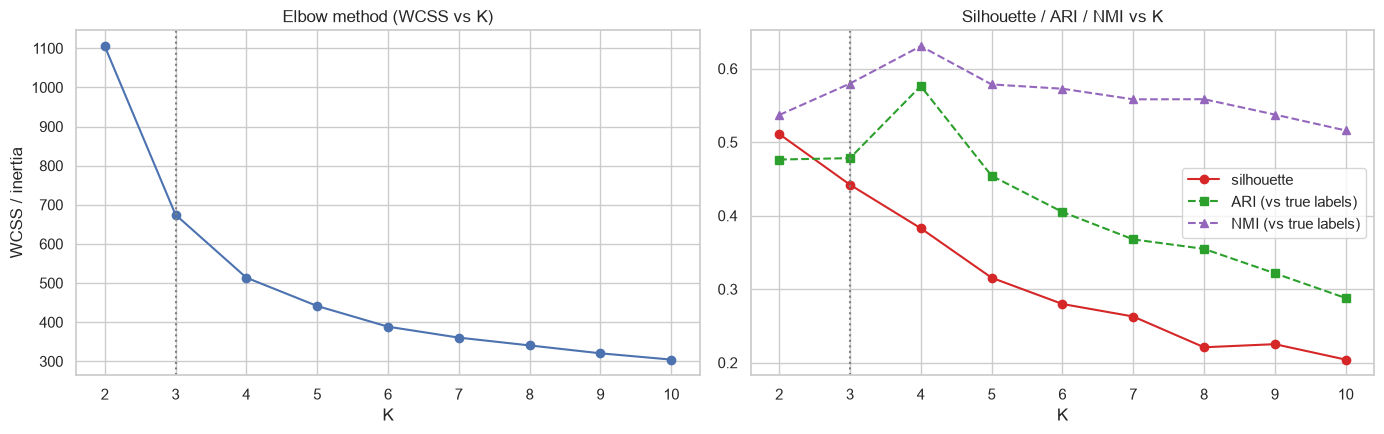

In [27]:
X_all = StandardScaler().fit_transform(feat[SELECTED].values)
y_all = feat[TARGET].values
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, init="k-means++", n_init=20, max_iter=300, random_state=SEED).fit(X_all)
    rows.append({"K": k, "WCSS": km.inertia_, "silhouette": silhouette_score(X_all, km.labels_),
                 "ARI": adjusted_rand_score(y_all, km.labels_), "NMI": normalized_mutual_info_score(y_all, km.labels_)})
km_tbl = pd.DataFrame(rows).set_index("K")
km_tbl["WCSS_drop_%"] = (-km_tbl["WCSS"].pct_change() * 100).round(1)
display(km_tbl.round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(km_tbl.index, km_tbl.WCSS, "o-"); axes[0].set_title("Elbow method (WCSS vs K)"); axes[0].set_xlabel("K"); axes[0].set_ylabel("WCSS / inertia")
axes[1].plot(km_tbl.index, km_tbl.silhouette, "o-", color="#d62728", label="silhouette")
axes[1].plot(km_tbl.index, km_tbl.ARI, "s--", color="#2ca02c", label="ARI (vs true labels)")
axes[1].plot(km_tbl.index, km_tbl.NMI, "^--", color="#9467bd", label="NMI (vs true labels)")
axes[1].set_title("Silhouette / ARI / NMI vs K"); axes[1].set_xlabel("K"); axes[1].legend()
for ax in axes: ax.axvline(3, color="grey", ls=":")
plt.tight_layout(); save("kmeans_elbow_silhouette"); plt.show()

**Choosing K (Elbow + Silhouette).**
* **WCSS** decreases from 1105 (K = 2) to 675 (K = 3) – the largest relative drop (**39 %**) – then 24 % (K = 4), 14 % (K = 5) and only 5–12 % afterwards. The curve bends clearly at **K = 3**, after which extra clusters mostly split existing groups.
* **Silhouette** is highest at K = 2 (0.511) and decreases monotonically (0.442 at K = 3, 0.383 at K = 4…). K = 2 separates "firm/green" fruit from "soft/ripe+overripe" fruit – the strongest density gap – but merges two ripeness stages.
* **ARI/NMI** (computed only for evaluation) are similar for K = 2 and 3 and peak at K = 4 (ARI 0.576), because a 4th cluster splits the heterogeneous Ripe/Unripe boundary region.
* **Decision: K = 3.** It is the elbow point, still has a reasonable silhouette (0.44 – moderate structure), and matches the number of ripeness stages, which makes the clusters interpretable. K = 2 and K = 4 are shown for comparison.

PCA explained variance (PC1, PC2): [0.838 0.069] total: 0.906


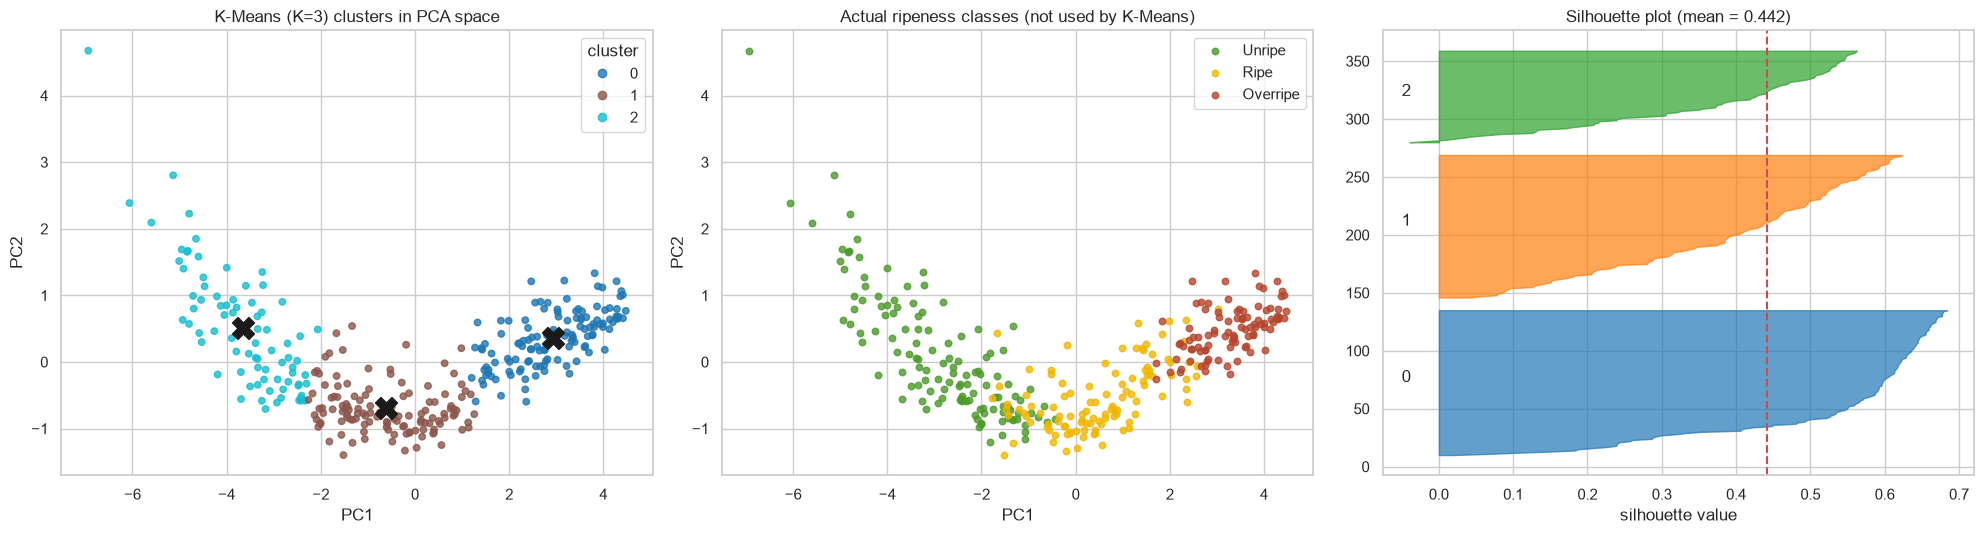

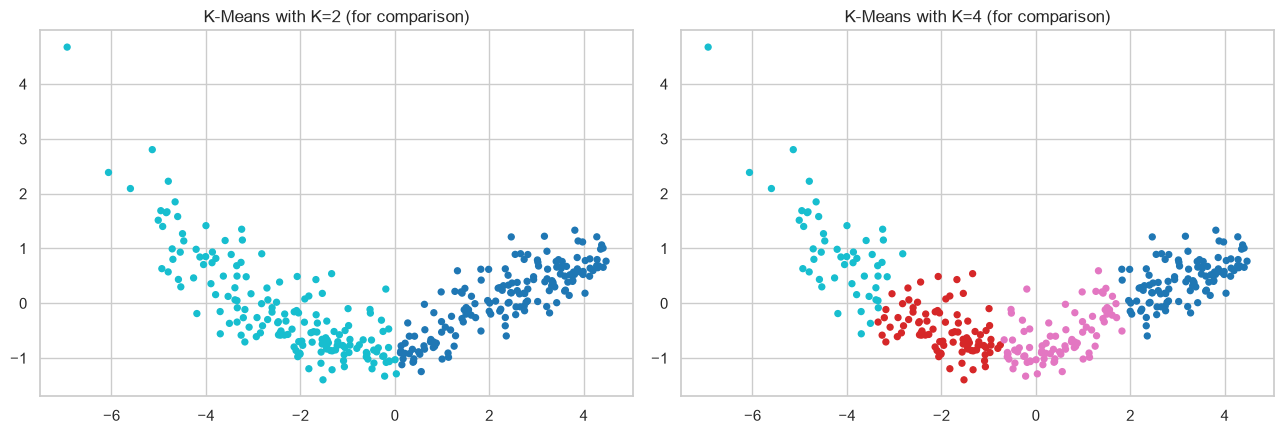

In [28]:
K_FINAL = 3
km = KMeans(n_clusters=K_FINAL, init="k-means++", n_init=20, max_iter=300, random_state=SEED).fit(X_all)
km_labels = km.labels_
pca = PCA(n_components=2, random_state=SEED).fit(X_all); Z = pca.transform(X_all)
print("PCA explained variance (PC1, PC2):", pca.explained_variance_ratio_.round(3), "total:", pca.explained_variance_ratio_.sum().round(3))

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
cent = pca.transform(km.cluster_centers_)
sc0 = axes[0].scatter(Z[:, 0], Z[:, 1], c=km_labels, cmap="tab10", s=22, alpha=.8)
axes[0].scatter(cent[:, 0], cent[:, 1], marker="X", s=250, c="k"); axes[0].set_title("K-Means (K=3) clusters in PCA space")
axes[0].legend(*sc0.legend_elements(), title="cluster")
for cl in CLASS_ORDER:
    m = y_all == cl; axes[1].scatter(Z[m, 0], Z[m, 1], c=PALETTE[cl], s=22, alpha=.8, label=cl)
axes[1].set_title("Actual ripeness classes (not used by K-Means)"); axes[1].legend()
sil = silhouette_samples(X_all, km_labels); yl = 10
for c in range(K_FINAL):
    v = np.sort(sil[km_labels == c]); axes[2].fill_betweenx(np.arange(yl, yl + len(v)), 0, v, alpha=.7, color=plt.cm.tab10(c))
    axes[2].text(-0.05, yl + len(v) / 2, str(c)); yl += len(v) + 10
axes[2].axvline(sil.mean(), color="r", ls="--"); axes[2].set_title(f"Silhouette plot (mean = {sil.mean():.3f})"); axes[2].set_xlabel("silhouette value")
for ax in axes[:2]: ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); save("kmeans_clusters_pca"); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, k in zip(axes, [2, 4]):
    lab = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit_predict(X_all)
    ax.scatter(Z[:, 0], Z[:, 1], c=lab, cmap="tab10", s=18); ax.set_title(f"K-Means with K={k} (for comparison)")
plt.tight_layout(); save("kmeans_k2_k4"); plt.show()

### Post-processing and interpretation of the K-Means clusters

Observations per cluster:


,n
km_cluster,
0,126
1,124
2,80


Average feature values per cluster (original units):


,thermal_time,tss_brix,acidity_pct,firmness_n,peel_hue_deg,aroma_score,log_dark_spots,days_after_harvest,firmness_per_100g
km_cluster,,,,,,,,,
0,269.98,20.94,0.31,8.66,66.94,7.00,3.25,14.33,3.19
1,143.20,14.63,0.62,20.10,84.94,3.73,0.08,7.50,6.96
2,52.39,10.14,1.15,43.77,100.71,1.78,0.00,3.02,16.13


ripeness_class,Unripe,Ripe,Overripe,dominant_class,purity
km_cluster,,,,,
0,0,31,95,Overripe,0.754
1,47,77,0,Ripe,0.621
2,80,0,0,Unripe,1.000


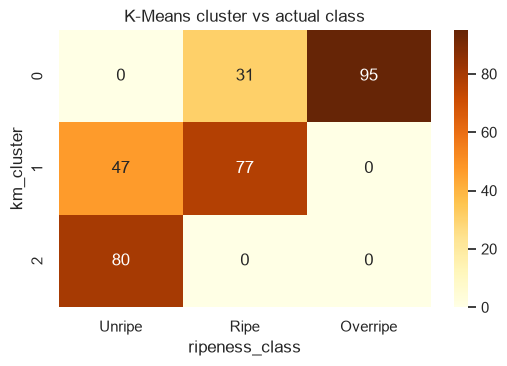

Observations in an 'unexpected' cluster (actual class ≠ cluster's dominant class): 78 / 330


,,count
ripeness_class,km_mapped,
Ripe,Overripe,31
Unripe,Ripe,47


,sample_id,variety,thermal_time,tss_brix,acidity_pct,firmness_n,peel_hue_deg,aroma_score,log_dark_spots,days_after_harvest,firmness_per_100g,ripeness_class,km_cluster,km_mapped
0,MG001,Anwar Ratol,127.36,11.37,0.84,27.16,90.1,5.2,0.00,6.4,13.03,Unripe,1,Ripe
7,MG008,Sindhri,103.04,11.21,0.86,33.27,86.1,2.5,0.00,5.6,11.77,Unripe,1,Ripe
13,MG014,Sindhri,205.84,19.82,0.45,17.72,71.8,5.2,1.39,12.4,3.20,Ripe,0,Overripe
18,MG019,Chaunsa,226.92,19.15,0.48,14.61,73.2,5.7,1.39,12.4,3.91,Ripe,0,Overripe
21,MG022,Sindhri,41.99,11.92,0.84,31.94,87.6,3.3,0.00,1.9,5.75,Unripe,1,Ripe
23,MG024,Sindhri,212.35,18.62,0.58,14.76,75.0,5.1,1.61,15.5,3.19,Ripe,0,Overripe
26,MG027,Chaunsa,134.25,12.35,0.70,22.71,91.8,2.1,0.00,7.5,8.78,Unripe,1,Ripe
29,MG030,Sindhri,139.50,12.87,0.81,30.08,88.6,4.6,0.00,9.0,5.79,Unripe,1,Ripe
35,MG036,Chaunsa,102.86,9.33,0.87,34.79,88.8,3.2,0.00,7.4,10.40,Unripe,1,Ripe
39,MG040,Sindhri,109.44,10.87,0.83,26.27,92.4,3.0,0.00,5.7,7.12,Unripe,1,Ripe


K-Means K=3 → Silhouette = 0.4421 | ARI = 0.4782 | NMI = 0.5797 | majority-mapped agreement = 0.7636


In [29]:
res = feat[["sample_id", "variety"] + SELECTED + [TARGET]].copy(); res["km_cluster"] = km_labels
print("Observations per cluster:"); display(res.km_cluster.value_counts().sort_index().to_frame("n"))
print("Average feature values per cluster (original units):")
display(res.groupby("km_cluster")[SELECTED].mean().round(2))
ct = pd.crosstab(res.km_cluster, res[TARGET])[CLASS_ORDER]
dom = ct.idxmax(axis=1); purity = ct.max(axis=1) / ct.sum(axis=1)
ct_show = ct.assign(dominant_class=dom, purity=purity.round(3)); display(ct_show)
fig, ax = plt.subplots(figsize=(6, 3.6)); sns.heatmap(ct, annot=True, fmt="d", cmap="YlOrBr", ax=ax)
ax.set_title("K-Means cluster vs actual class"); save("kmeans_crosstab"); plt.show()

# Majority-class mapping (illustrative only, explained in markdown)
res["km_mapped"] = res.km_cluster.map(dom)
unexpected = res[res.km_mapped != res[TARGET]]
print(f"Observations in an 'unexpected' cluster (actual class ≠ cluster's dominant class): {len(unexpected)} / {len(res)}")
display(unexpected.groupby([TARGET, "km_mapped"]).size().to_frame("count"))
display(unexpected.head(12).round(2))
km_sil, km_ari, km_nmi = silhouette_score(X_all, km_labels), adjusted_rand_score(y_all, km_labels), normalized_mutual_info_score(y_all, km_labels)
print(f"K-Means K=3 → Silhouette = {km_sil:.4f} | ARI = {km_ari:.4f} | NMI = {km_nmi:.4f} | majority-mapped agreement = {(res.km_mapped == res[TARGET]).mean():.4f}")
RESULTS["kmeans"] = {"K": K_FINAL, "silhouette": km_sil, "ARI": km_ari, "NMI": km_nmi, "mapped_agreement": float((res.km_mapped == res[TARGET]).mean()),
                     "sizes": res.km_cluster.value_counts().sort_index().tolist(), "dominant": dom.to_dict(), "purity": purity.round(3).to_dict(),
                     "table": km_tbl.round(4).reset_index().to_dict(orient="records")}

**Interpretation of the K-Means clusters (K = 3).**
* **Cluster sizes:** 126 / 124 / 80 mangoes (clusters 0 / 1 / 2).
* **Cluster profiles (mean feature values):**
  * *Cluster 2 – "green & hard"*: firmness 43.8 N, Brix 10.1, acidity 1.15 %, hue 100.7°, aroma 1.8, no spots, 3 days. **100 % Unripe** (80/80).
  * *Cluster 1 – "turning / mid-ripe"*: firmness 20.1 N, Brix 14.6, acidity 0.62 %, hue 84.9°, aroma 3.7, 7.5 days. Dominant class **Ripe** (77/124 = 62 %), with 47 late-Unripe mangoes.
  * *Cluster 0 – "soft, sweet, spotted"*: firmness 8.7 N, Brix 20.9, acidity 0.31 %, hue 66.9°, aroma 7.0, many spots, 14 days. Dominant class **Overripe** (95/126 = 75 %), with 31 late-Ripe mangoes.
* **Dominant classes and unexpected observations:** using majority mapping (cluster → most frequent class in it), 78 of 330 mangoes (24 %) fall into an “unexpected” cluster: 47 Unripe in the mid-ripe cluster and 31 Ripe in the soft cluster. **No Unripe mango is in the over-ripe cluster and no Overripe mango in the green cluster.** The unexpected mangoes are the late-stage members of their class (e.g. MG014, MG019, MG024: labelled Ripe but already 12–15 days old with spots and Brix ≈19–20).
* **Why the boundaries are shifted:** K-Means minimises squared distances and prefers compact, similar-variance groups. The very firm, green fruit form a tight group far from the rest, so K-Means gives them their own cluster and pushes the boundaries towards the ripe end. The grader's thresholds (on the hidden ripening stage) do not have to coincide with the WCSS-optimal cuts of a continuous ripening gradient.
* **Are the clusters meaningful?** Yes. Without seeing any label, K-Means recovered an ordered **ripening gradient** – green/hard → turning → soft/sweet/spotted – with every centroid ordered in the same direction on every feature (ARI 0.478, NMI 0.580, far above the 0 expected for random grouping). The clusters are best read as *ripeness segments* rather than an exact copy of the grader's classes. The moderate silhouette (0.44) reflects that the data form a continuum with only one strong gap (between hard-green fruit and the rest).

## 6. Phase V – Agglomerative Hierarchical Clustering  *(Deliverable 7)*

### How agglomerative clustering works
It is a **bottom-up** method: (1) start with every mango as its own cluster (n = 330 clusters), (2) compute the distance between every pair of clusters, (3) merge the two closest clusters, (4) repeat until one cluster remains. The sequence of merges forms a tree – the **dendrogram** – and cutting the tree at some height gives a flat clustering.

The **linkage** defines the distance between two clusters A and B:
| Linkage | Cluster distance | Typical behaviour |
|---|---|---|
| **Single** | min distance between any a∈A, b∈B | Finds elongated shapes but suffers from *chaining* – one giant cluster plus singletons |
| **Complete** | max distance between any a∈A, b∈B | Compact clusters of similar diameter; sensitive to outliers |
| **Average** (UPGMA) | mean of all pairwise distances | Compromise between single and complete |
| **Ward** | increase in total WCSS caused by merging | Compact, similar-sized, spherical clusters (same objective as K-Means); requires Euclidean distance |

Scikit-learn's `AgglomerativeClustering(n_clusters, linkage, metric="euclidean")` is used for the flat assignments, and SciPy's `linkage()` for the full merge tree/dendrogram (scikit-learn does not draw dendrograms). Labels are not used for fitting.

,linkage,n_clusters,silhouette,ARI,NMI,cluster_sizes
0,single,2,0.5437,-0.0009,0.0052,"[329, 1]"
1,single,3,0.2721,-0.0017,0.0103,"[328, 1, 1]"
2,single,4,0.2044,-0.0025,0.0152,"[327, 1, 1, 1]"
3,single,5,0.0783,-0.0032,0.0199,"[326, 1, 1, 1, 1]"
4,single,6,0.0720,-0.0040,0.0245,"[325, 1, 1, 1, 1, 1]"
5,complete,2,0.4010,0.0971,0.2703,"[269, 61]"
6,complete,3,0.3617,0.4022,0.5202,"[183, 86, 61]"
7,complete,4,0.3515,0.3994,0.5164,"[183, 86, 60, 1]"
8,complete,5,0.3303,0.5594,0.6060,"[110, 86, 73, 60, 1]"
9,complete,6,0.3147,0.5303,0.5845,"[110, 86, 73, 48, 12, 1]"


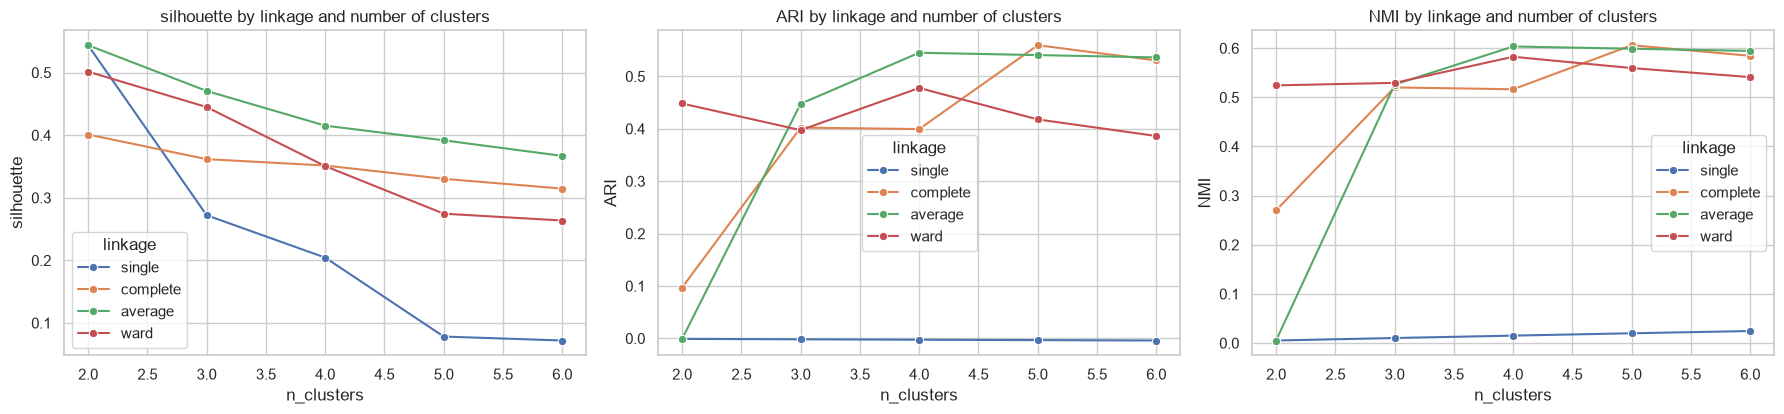

In [30]:
LINKS = ["single", "complete", "average", "ward"]
rows, agg_labels = [], {}
for link in LINKS:
    for k in range(2, 7):
        lab = AgglomerativeClustering(n_clusters=k, linkage=link, metric="euclidean").fit_predict(X_all)
        agg_labels[(link, k)] = lab
        sizes = np.bincount(lab)
        rows.append({"linkage": link, "n_clusters": k, "silhouette": silhouette_score(X_all, lab), "ARI": adjusted_rand_score(y_all, lab),
                     "NMI": normalized_mutual_info_score(y_all, lab), "cluster_sizes": sorted(sizes.tolist(), reverse=True)})
agg_tbl = pd.DataFrame(rows)
display(agg_tbl.round(4))
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
for ax, m in zip(axes, ["silhouette", "ARI", "NMI"]):
    sns.lineplot(agg_tbl, x="n_clusters", y=m, hue="linkage", marker="o", ax=ax); ax.set_title(f"{m} by linkage and number of clusters")
plt.tight_layout(); save("agg_metrics_by_linkage"); plt.show()

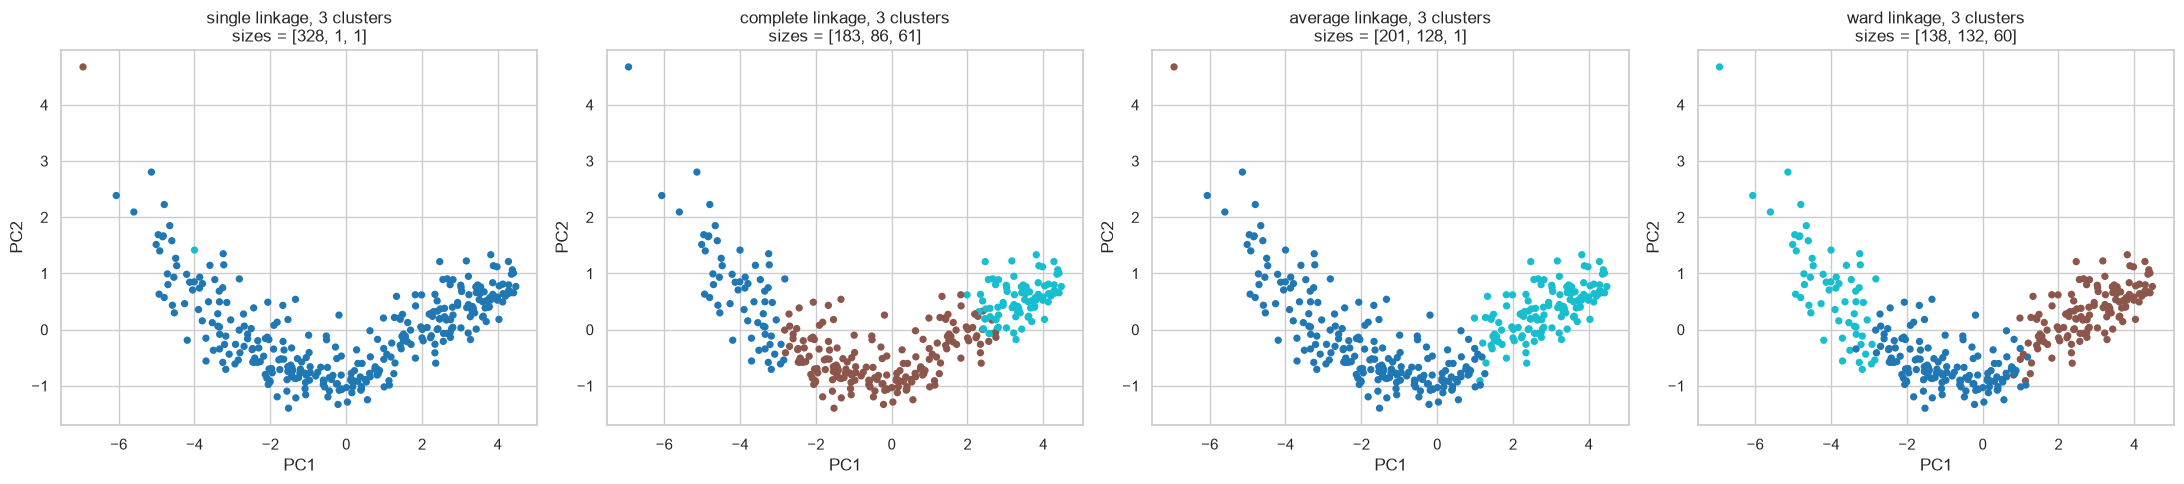

In [31]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
for ax, link in zip(axes, LINKS):
    lab = agg_labels[(link, 3)]
    ax.scatter(Z[:, 0], Z[:, 1], c=lab, cmap="tab10", s=18)
    ax.set_title(f"{link} linkage, 3 clusters\nsizes = {sorted(np.bincount(lab).tolist(), reverse=True)}")
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout(); save("agg_linkage_pca"); plt.show()

**Comparison of linkage methods.**
* **Single linkage** produces one giant cluster plus singletons for every number of clusters (e.g. [328, 1, 1] at k = 3) and ARI ≈ 0. Its high silhouette at k = 2 (0.54) is misleading – it just isolates one extreme mango. This is the well-known **chaining effect**: in a continuum of points, there is always a chain of close neighbours linking all fruit, so single linkage can only cut off isolated outliers.
* **Average linkage** also starts by isolating an outlier (k = 2: [329, 1]) but from k = 3 it finds real structure (k = 4: [128, 104, 97, 1], ARI 0.545, silhouette 0.415).
* **Complete linkage** creates more balanced groups (k = 3: [183, 86, 61]); its clusters depend on the maximum pairwise distance, so it is sensitive to a few far points (a singleton appears from k = 4).
* **Ward linkage** gives balanced, compact clusters at every k ([138, 132, 60] at k = 3) with a high silhouette (0.445 at k = 3) and no singletons, because it merges the pair of clusters that increases the total WCSS the least – the same objective as K-Means.
* **Number of clusters:** for Ward and complete, silhouette falls as k grows while ARI/NMI are highest around k = 4–5, again because extra clusters split the Unripe/Ripe boundary region. k = 3 is kept as the final choice for comparability with K-Means and the three ripeness stages, and because the dendrogram (below) shows a large jump before the 3-cluster level.

### Dendrograms

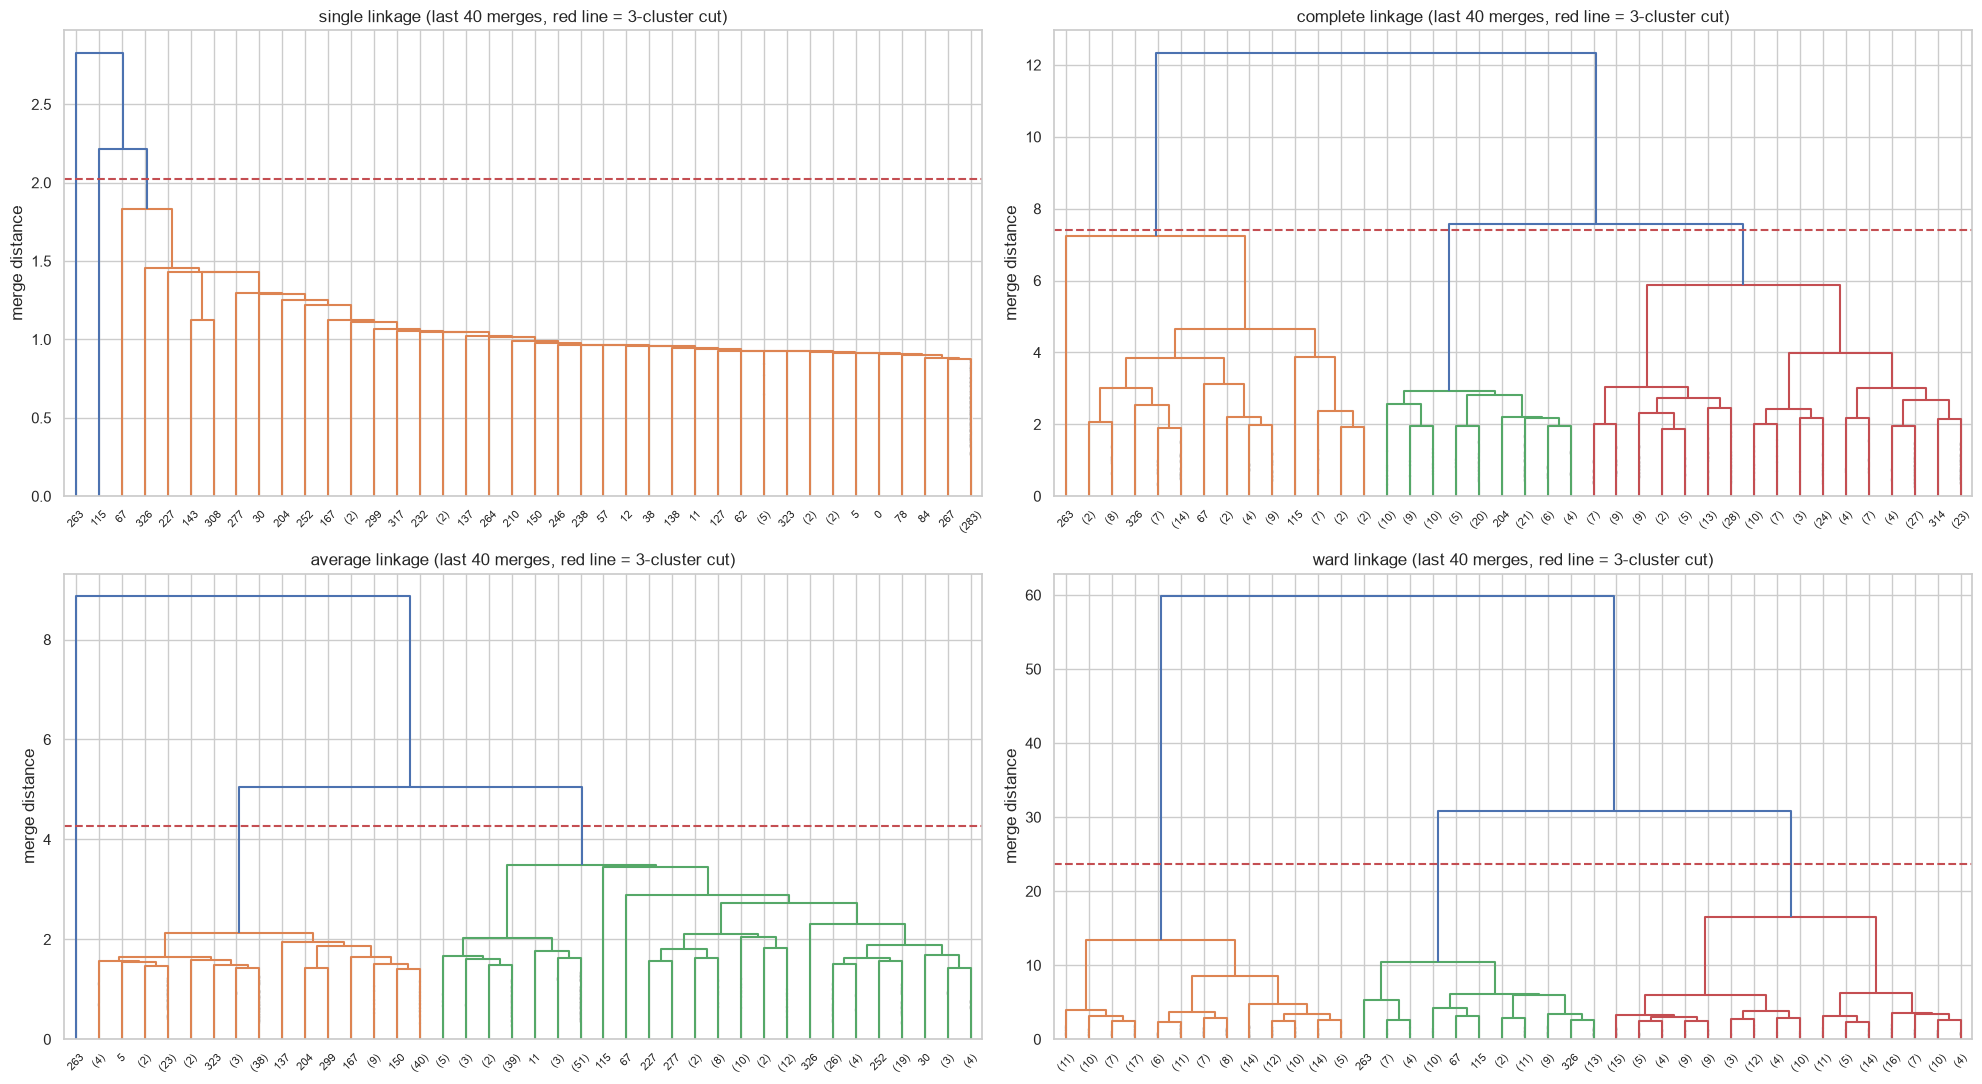

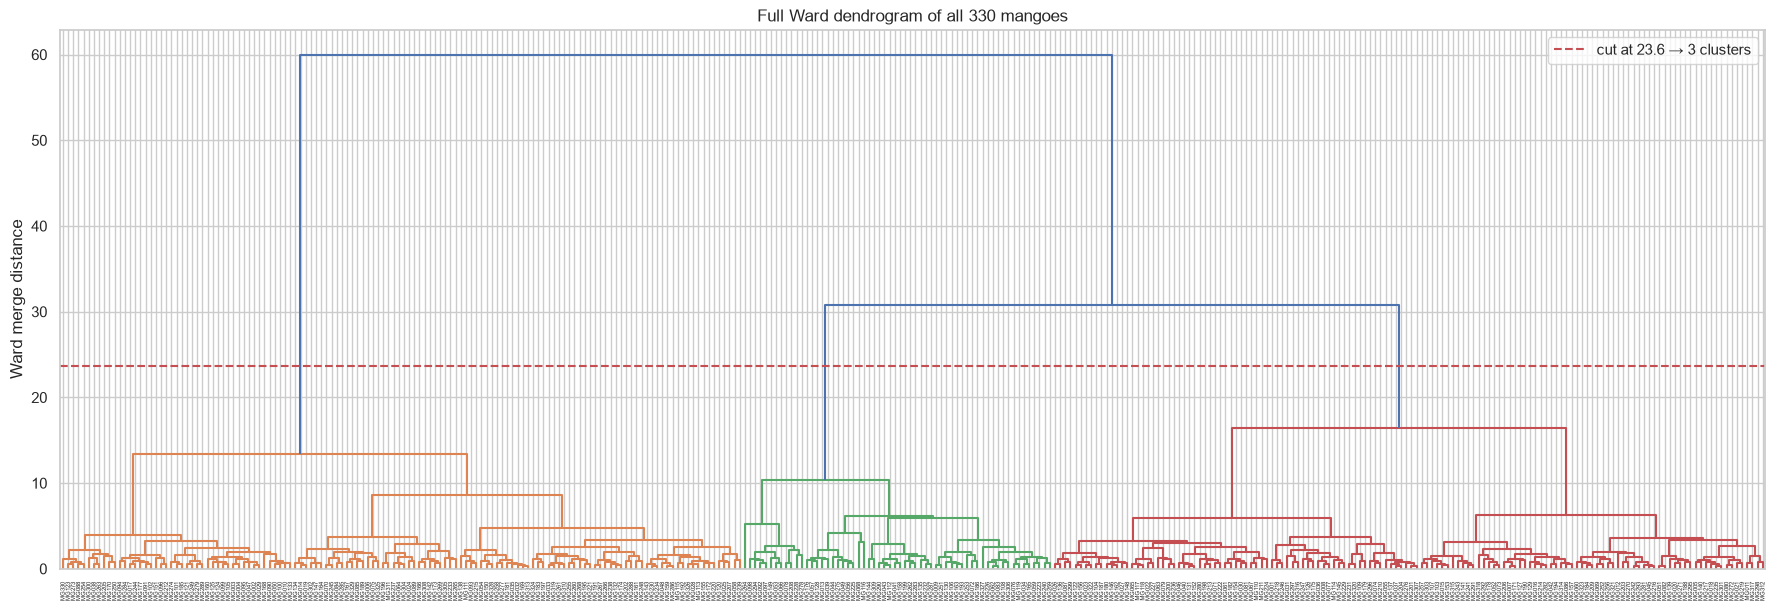

In [32]:
Lmats = {link: linkage(X_all, method=link, metric="euclidean") for link in LINKS}
fig, axes = plt.subplots(2, 2, figsize=(20, 11)); axes = axes.ravel()
for ax, link in zip(axes, LINKS):
    L = Lmats[link]; cut = (L[-3, 2] + L[-2, 2]) / 2         # height giving 3 clusters
    dendrogram(L, truncate_mode="lastp", p=40, ax=ax, color_threshold=cut, show_contracted=True, leaf_font_size=8)
    ax.axhline(cut, color="r", ls="--"); ax.set_title(f"{link} linkage (last 40 merges, red line = 3-cluster cut)"); ax.set_ylabel("merge distance")
plt.tight_layout(); save("agg_dendrograms_all"); plt.show()

L = Lmats["ward"]; cut3 = (L[-3, 2] + L[-2, 2]) / 2
fig, ax = plt.subplots(figsize=(22, 7))
dendrogram(L, labels=feat["sample_id"].values, color_threshold=cut3, ax=ax, leaf_font_size=4)
ax.axhline(cut3, color="r", ls="--", label=f"cut at {cut3:.1f} → 3 clusters"); ax.legend()
ax.set_title("Full Ward dendrogram of all 330 mangoes"); ax.set_ylabel("Ward merge distance")
save("agg_dendrogram_ward_full"); plt.show()

### Which observations / clusters merge at different stages?

EARLY STAGE – first 10 merges (most similar individual mangoes):


,step,merged_A,merged_B,distance,new_size
0,1,MG051,MG082,0.271,2
1,2,MG169,MG313,0.319,2
2,3,MG062,MG083,0.329,2
3,4,MG159,MG286,0.348,2
4,5,MG131,MG152,0.350,2
5,6,MG235,MG301,0.360,2
6,7,MG045,MG216,0.366,2
7,8,MG007,MG171,0.371,2
8,9,MG230,MG234,0.378,2
9,10,MG037,MG204,0.378,2


,sample_id,variety,thermal_time,tss_brix,acidity_pct,firmness_n,peel_hue_deg,aroma_score,log_dark_spots,days_after_harvest,firmness_per_100g,ripeness_class
50,MG051,Anwar Ratol,188.32,17.08,0.65,13.34,83.8,3.8,0.0,8.8,8.60,Ripe
81,MG082,Anwar Ratol,183.68,16.86,0.68,15.22,82.0,3.5,0.0,8.2,8.17,Ripe


,sample_id,variety,thermal_time,tss_brix,acidity_pct,firmness_n,peel_hue_deg,aroma_score,log_dark_spots,days_after_harvest,firmness_per_100g,ripeness_class
168,MG169,Chaunsa,280.00,21.11,0.18,6.97,60.4,7.4,3.83,12.5,2.82,Overripe
312,MG313,Chaunsa,277.97,22.00,0.20,6.94,61.9,7.0,3.83,13.3,3.04,Overripe


,sample_id,variety,thermal_time,tss_brix,acidity_pct,firmness_n,peel_hue_deg,aroma_score,log_dark_spots,days_after_harvest,firmness_per_100g,ripeness_class
61,MG062,Sindhri,75.04,8.76,1.06,43.34,102.4,2.1,0.0,2.8,10.88,Unripe
82,MG083,Sindhri,64.53,9.39,1.06,46.07,102.8,2.6,0.0,2.7,11.11,Unripe


MIDDLE STAGE – merges 160-165:


,step,merged_A,merged_B,distance,new_size
159,160,MG036,cluster#390 (2),0.890,3
160,161,MG120,cluster#471 (2),0.894,3
161,162,MG094,MG284,0.900,2
162,163,cluster#402 (3),cluster#440 (3),0.901,6
163,164,MG054,cluster#383 (2),0.911,3
164,165,MG199,cluster#418 (2),0.915,3


FINAL STAGE – last 8 merges (large groups joined):


,step,merged_A,merged_B,distance,new_size
321,322,cluster#646 (12),cluster#649 (36),6.124,48
322,323,cluster#635 (30),cluster#642 (37),6.225,67
323,324,cluster#643 (32),cluster#647 (55),8.610,87
324,325,cluster#648 (12),cluster#651 (48),10.414,60
325,326,cluster#645 (45),cluster#653 (87),13.355,132
326,327,cluster#650 (71),cluster#652 (67),16.482,138
327,328,cluster#654 (60),cluster#656 (138),30.803,198
328,329,cluster#655 (132),cluster#657 (198),59.893,330


cluster#657: size 198 → {'Unripe': 127, 'Ripe': 71, 'Overripe': 0}
cluster#656: size 138 → {'Unripe': 67, 'Ripe': 71, 'Overripe': 0}
cluster#655: size 132 → {'Unripe': 0, 'Ripe': 37, 'Overripe': 95}
cluster#654: size 60 → {'Unripe': 60, 'Ripe': 0, 'Overripe': 0}


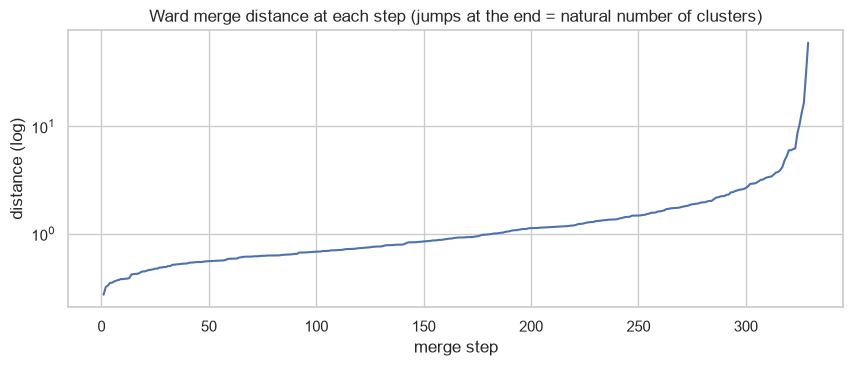

Last 6 merge distances: [ 8.61 10.41 13.35 16.48 30.8  59.89]


In [33]:
ids = feat["sample_id"].values; n = len(ids)
members = {i: [ids[i]] for i in range(n)}
log = []
for step, (a, b, d, size) in enumerate(L, start=1):
    a, b = int(a), int(b)
    members[n + step - 1] = members[a] + members[b]
    log.append({"step": step, "merged_A": members[a][0] if len(members[a]) == 1 else f"cluster#{a} ({len(members[a])})",
                "merged_B": members[b][0] if len(members[b]) == 1 else f"cluster#{b} ({len(members[b])})",
                "distance": d, "new_size": int(size)})
log = pd.DataFrame(log)
print("EARLY STAGE – first 10 merges (most similar individual mangoes):"); display(log.head(10).round(3))
first_pairs = [(log.merged_A[i], log.merged_B[i]) for i in range(3)]
for a_, b_ in first_pairs:
    if not a_.startswith("cluster"):
        display(feat.loc[feat.sample_id.isin([a_, b_]), ["sample_id", "variety"] + SELECTED + [TARGET]].round(2))
print("MIDDLE STAGE – merges 160-165:"); display(log.iloc[159:165].round(3))
print("FINAL STAGE – last 8 merges (large groups joined):"); display(log.tail(8).round(3))
# class composition of the clusters joined in the last merges
for node in [2 * n - 2 - j for j in range(1, 5)]:
    mem = members[node]; comp = feat.loc[feat.sample_id.isin(mem), TARGET].value_counts().reindex(CLASS_ORDER, fill_value=0)
    print(f"cluster#{node}: size {len(mem)} → {comp.to_dict()}")
fig, ax = plt.subplots(figsize=(10, 3.6)); ax.plot(log.step, log.distance); ax.set_yscale("log")
ax.set_title("Ward merge distance at each step (jumps at the end = natural number of clusters)"); ax.set_xlabel("merge step"); ax.set_ylabel("distance (log)")
save("agg_merge_distance"); plt.show()
print("Last 6 merge distances:", L[-6:, 2].round(2))

**Reading the dendrogram and the merge sequence.**
* **Early stages (bottom of the tree):** the very first merges join nearly identical fruit at distances of ≈0.3, e.g. MG051 + MG082 (both Ripe Anwar Ratol, 17 °Brix, firmness 13–15 N, hue 82–84°), MG169 + MG313 (both Overripe Chaunsa, Brix 21–22, hue ≈61°) and MG062 + MG083 (both Unripe Sindhri, ≈45 N, hue ≈102°). Early merges are always within one class – the most similar mangoes share the same ripeness stage.
* **Middle stages (steps ≈160–165, distance ≈0.9):** singletons join small groups of 2–3 fruit, building local “neighbourhoods” of similar ripeness.
* **Final stages (top of the tree):** the merge distance jumps from 16.5 to **30.8** and then to **59.9**. The last merge (59.9) joins a 132-fruit cluster that contains all Overripe fruit (95 Overripe + 37 Ripe) with a 198-fruit cluster of Unripe and Ripe fruit. The step before (30.8) joins the 60 hardest green mangoes (100 % Unripe) to the 138-fruit “Unripe/Ripe” group. These large vertical gaps show that **2–3 clusters is the natural level** of the hierarchy; cutting at the red line (between 16.5 and 30.8) gives the 3 Ward clusters.
* The merge-distance plot is almost flat for 320 steps and explodes in the last ≈5 merges, the typical shape when a few large groups exist.
* The four dendrograms differ strongly: single and average linkage show long thin “staircases” (chaining, merges at similar heights), whereas complete and especially Ward show a few well separated branches.

### Post-processing of the final agglomerative assignment (Ward, 3 clusters)

Observations per cluster:


,n
agg_cluster,
0,138
1,132
2,60


,thermal_time,tss_brix,acidity_pct,firmness_n,peel_hue_deg,aroma_score,log_dark_spots,days_after_harvest,firmness_per_100g
agg_cluster,,,,,,,,,
0,131.42,13.86,0.65,22.71,86.62,3.47,0.04,6.89,7.76
1,266.78,20.84,0.32,8.83,67.40,6.88,3.14,14.25,3.25
2,43.60,10.02,1.26,46.41,102.87,1.65,0.00,2.41,17.59


ripeness_class,Unripe,Ripe,Overripe,dominant_class,purity
agg_cluster,,,,,
0,67,71,0,Ripe,0.514
1,0,37,95,Overripe,0.720
2,60,0,0,Unripe,1.000


Unexpected assignments: 104


,,count
ripeness_class,agg_mapped,
Ripe,Overripe,37
Unripe,Ripe,67


... (4 outputs left out)


AVERAGE linkage – cluster vs class


col_0,Unripe,Ripe,Overripe
row_0,,,
0,126,75,0
1,1,0,0
2,0,33,95



WARD linkage – cluster vs class


col_0,Unripe,Ripe,Overripe
row_0,,,
0,67,71,0
1,0,37,95
2,60,0,0


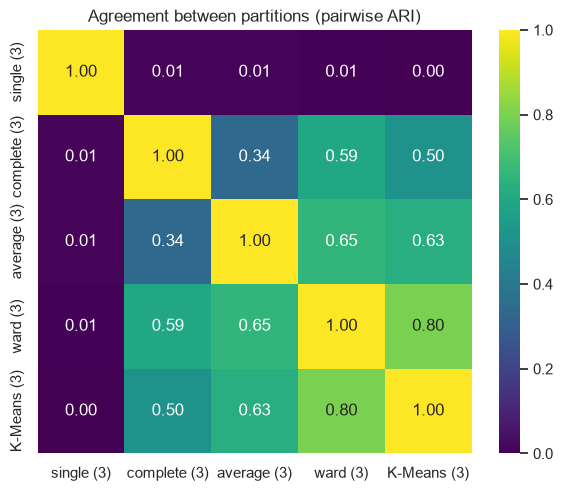

Ward K=3 → Silhouette = 0.4449 | ARI = 0.3974 | NMI = 0.5294 | majority-mapped agreement = 0.6848


In [34]:
agg_final = agg_labels[("ward", 3)]
res["agg_cluster"] = agg_final
print("Observations per cluster:"); display(res.agg_cluster.value_counts().sort_index().to_frame("n"))
display(res.groupby("agg_cluster")[SELECTED].mean().round(2))
ct_a = pd.crosstab(res.agg_cluster, res[TARGET])[CLASS_ORDER]
dom_a = ct_a.idxmax(axis=1); pur_a = ct_a.max(axis=1) / ct_a.sum(axis=1)
display(ct_a.assign(dominant_class=dom_a, purity=pur_a.round(3)))
res["agg_mapped"] = res.agg_cluster.map(dom_a)
print("Unexpected assignments:", int((res.agg_mapped != res[TARGET]).sum()))
display(res[res.agg_mapped != res[TARGET]].groupby([TARGET, "agg_mapped"]).size().to_frame("count"))

# per-linkage class composition at 3 clusters
for link in LINKS:
    c = pd.crosstab(agg_labels[(link, 3)], y_all)[CLASS_ORDER]
    print(f"\n{link.upper()} linkage – cluster vs class"); display(c)

# Do different linkages give significantly different groupings? (pairwise ARI between partitions)
parts = {f"{l} (3)": agg_labels[(l, 3)] for l in LINKS}; parts["K-Means (3)"] = km_labels
pair = pd.DataFrame([[adjusted_rand_score(parts[a], parts[b]) for b in parts] for a in parts], index=parts, columns=parts)
fig, ax = plt.subplots(figsize=(7, 5.5)); sns.heatmap(pair, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1, ax=ax)
ax.set_title("Agreement between partitions (pairwise ARI)"); save("agg_partition_agreement"); plt.show()

ag_sil, ag_ari, ag_nmi = silhouette_score(X_all, agg_final), adjusted_rand_score(y_all, agg_final), normalized_mutual_info_score(y_all, agg_final)
print(f"Ward K=3 → Silhouette = {ag_sil:.4f} | ARI = {ag_ari:.4f} | NMI = {ag_nmi:.4f} | majority-mapped agreement = {(res.agg_mapped == res[TARGET]).mean():.4f}")
RESULTS["agg"] = {"linkage": "ward", "K": 3, "silhouette": ag_sil, "ARI": ag_ari, "NMI": ag_nmi, "mapped_agreement": float((res.agg_mapped == res[TARGET]).mean()),
                  "sizes": res.agg_cluster.value_counts().sort_index().tolist(), "dominant": dom_a.to_dict(), "purity": pur_a.round(3).to_dict(),
                  "table": agg_tbl.assign(cluster_sizes=agg_tbl.cluster_sizes.astype(str)).round(4).to_dict(orient="records"),
                  "pairwise_ari": pair.round(3).to_dict()}

**Interpretation of the final agglomerative clusters (Ward, 3 clusters).**
* **Cluster sizes:** 138 / 132 / 60.
* **Profiles and dominant classes:**
  * *Cluster 2 (60)* – firmness 46.4 N, Brix 10.0, hue 102.9°, 2.4 days: the hardest, greenest fruit – **100 % Unripe**.
  * *Cluster 0 (138)* – firmness 22.7 N, Brix 13.9, hue 86.6°: mixture of late-Unripe (67) and Ripe (71) fruit – dominant **Ripe** but only 51 % purity.
  * *Cluster 1 (132)* – firmness 8.8 N, Brix 20.8, hue 67.4°, many spots: **Overripe** dominant (95/132 = 72 %) with 37 late-Ripe.
* **Unexpected assignments:** 104 (67 Unripe in the mixed cluster, 37 Ripe in the over-ripe cluster); again no Unripe↔Overripe mixing.
* **Comparison of structures:** at 3 clusters, Ward (ARI 0.397, NMI 0.529) and average linkage (ARI 0.448) are close to K-Means (ARI 0.478, NMI 0.580); complete linkage is similar (0.402) but with different cluster sizes; single linkage is useless (ARI ≈ 0). The pairwise-ARI heat-map shows that Ward and K-Means produce very similar partitions (ARI 0.80 – both minimise within-cluster variance), average linkage agrees moderately with both (0.65 / 0.63), complete linkage less (0.60 / 0.50, and only 0.34 with average), while single linkage agrees with nobody (ARI ≤ 0.01).
* **Do linkages produce significantly different groupings?** **Yes.** The linkage choice changes the result far more than the number of clusters: single/average isolate outliers at low k, complete gives a large mixed group, and Ward gives balanced groups. For this kind of data (a continuous gradient with no large gaps and a few extreme points), Ward or average linkage are appropriate; single linkage is not.
* Like K-Means, Ward finds a meaningful **ordered ripening structure** – hard-green → intermediate → soft-spotted – but places the first boundary earlier than the grader (it isolates the very green fruit), which explains its lower ARI than K-Means.

## 7. Phase VI – Comparative Analysis and Final Interpretation  *(Deliverable 8)*
Classification and clustering solve **different tasks**, so they are evaluated with different metrics:
* KNN (supervised) → accuracy, precision, recall, F1 on held-out labelled test data.
* K-Means / Agglomerative (unsupervised) → **internal** quality (Silhouette, no labels needed) and **external** agreement with the ground truth (ARI, NMI), which are invariant to the arbitrary numbering of clusters.

**ARI (Adjusted Rand Index)** counts pairs of mangoes that are placed together/apart consistently in the clustering and in the true classes, corrected for chance (0 ≈ random, 1 = identical partition). **NMI (Normalized Mutual Information)** measures the information shared between cluster IDs and class labels, normalised to 0…1.

**Majority-class mapping (illustrative only).** Because cluster numbers are arbitrary, cluster IDs were never compared directly with labels. For an illustration only, each cluster was mapped to the most frequent actual class among its members (`dominant_class` in the cross-tabs), and the share of mangoes whose actual class equals their cluster's mapped class was computed. This uses the labels *after* clustering, so it is not a prediction accuracy and is not comparable with KNN's test accuracy.

,KNN,K-Means,Agglomerative
Learning type,Supervised,Unsupervised,Unsupervised
Labels used during fitting,Yes,No,No
Accuracy on held-out labels,0.880 (macro-F1 0.876),Not directly applicable,Not directly applicable
Silhouette Score,Not applicable,0.442,0.445
ARI / NMI,Not applicable,0.478 / 0.580,0.397 / 0.529
Majority-mapped agreement (illustrative),Not applicable,0.764,0.685
Final configuration,"K=3, manhattan, uniform voting","K=3, k-means++, n_init=20","Ward linkage, 3 clusters"


,silhouette,ARI,NMI
linkage,,,
single,0.272,-0.002,0.010
complete,0.362,0.402,0.520
average,0.471,0.448,0.526
ward,0.445,0.397,0.529
K-Means,0.442,0.478,0.580


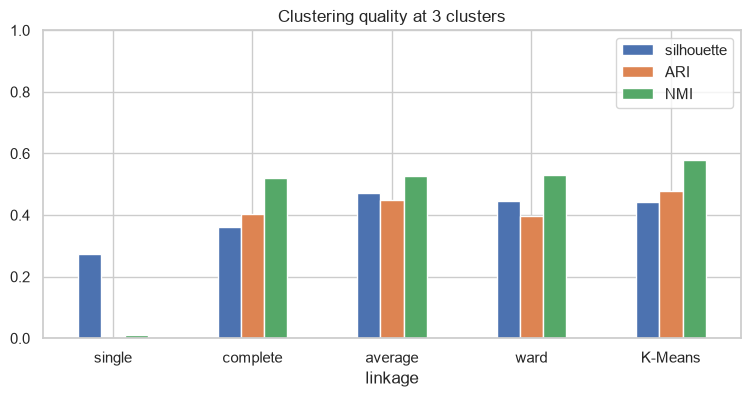

In [35]:
K_ = RESULTS["knn"]; M_ = RESULTS["kmeans"]; A_ = RESULTS["agg"]
comp = pd.DataFrame({
    "KNN": ["Supervised", "Yes", f"{K_['test_acc']:.3f} (macro-F1 {K_['macro_f1']:.3f})", "Not applicable", "Not applicable", "Not applicable",
            f"K={K_['K']}, {K_['metric']}, {K_['weights']} voting"],
    "K-Means": ["Unsupervised", "No", "Not directly applicable", f"{M_['silhouette']:.3f}", f"{M_['ARI']:.3f} / {M_['NMI']:.3f}",
                f"{M_['mapped_agreement']:.3f}", "K=3, k-means++, n_init=20"],
    "Agglomerative": ["Unsupervised", "No", "Not directly applicable", f"{A_['silhouette']:.3f}", f"{A_['ARI']:.3f} / {A_['NMI']:.3f}",
                      f"{A_['mapped_agreement']:.3f}", "Ward linkage, 3 clusters"]},
    index=["Learning type", "Labels used during fitting", "Accuracy on held-out labels", "Silhouette Score", "ARI / NMI",
           "Majority-mapped agreement (illustrative)", "Final configuration"])
display(comp)
best_alt = agg_tbl[agg_tbl.n_clusters == 3].set_index("linkage")[["silhouette", "ARI", "NMI"]]
best_alt.loc["K-Means"] = [M_["silhouette"], M_["ARI"], M_["NMI"]]
display(best_alt.round(3))
fig, ax = plt.subplots(figsize=(9, 4)); best_alt.plot.bar(ax=ax); ax.set_title("Clustering quality at 3 clusters"); ax.set_ylim(0, 1); plt.xticks(rotation=0)
save("comparison_clustering"); plt.show()
RESULTS["comparison"] = comp.to_dict(); RESULTS["clust_k3"] = best_alt.round(4).to_dict(orient="index")

### Main observations
| | KNN | K-Means | Agglomerative (Ward) |
|---|---|---|---|
| **Main observations** | Very good supervised performance: test accuracy 0.880, macro-F1 0.876 (CV accuracy 0.931). All errors are between adjacent stages; Ripe is the hardest class (recall 0.74). Feature selection improved CV accuracy from 0.903 (raw) to 0.931. | Without labels, recovered an ordered ripening gradient (green → turning → soft). Best external agreement of the clustering methods (ARI 0.478, NMI 0.580); one perfectly pure Unripe cluster. Elbow at K = 3. | Similar ordered structure, balanced clusters, silhouette 0.445 (highest with average linkage at k = 3); dendrogram shows natural 2–3 group structure. ARI 0.397 / NMI 0.529. Linkage choice matters strongly (single linkage fails through chaining). |
| **Limitations** | Needs labelled data; stores the whole training set and computes all distances at prediction time (slow for big data); sensitive to scaling and irrelevant features (shown by the ablation); sensitive to label noise near boundaries; small test set → ±3–4 % uncertainty. | K must be chosen in advance; assumes spherical, similar-size clusters; sensitive to initialisation (mitigated by k-means++, n_init = 20) and outliers; cannot model a continuum – it cuts it at WCSS-optimal points that do not match the grader's thresholds. | O(n²) memory/time – fine for 330 fruit but not for large data; merges are greedy and can never be undone; result depends heavily on the linkage; Ward assumes Euclidean distance; single/average are sensitive to outliers. |

### Interpretation
1. **Supervised vs unsupervised.** KNN is told what "ripe" means (labels) and reaches ≈88–93 % accuracy. The clustering methods are never told and still discover groups that are strongly related to ripeness (NMI ≈ 0.53–0.58). The ripeness classes are therefore a **real structure in the measurements**, not just a convention of the grader.
2. **Why clustering agrees only moderately with labels.** The classes are thresholds on a continuous ripening process. Distance-based clustering looks for compact groups; the most compact, isolated group is the very hard green fruit, so both K-Means and Ward devote one cluster to it and merge the Ripe class with its neighbours. Labels are needed to place the boundaries exactly where the grader does – that is the value of supervision.
3. **Internal vs external metrics disagree.** Silhouette prefers K = 2 and even rewards single linkage for isolating one outlier, whereas ARI/NMI prefer 3–4 clusters. Internal metrics measure geometric compactness, not usefulness, so both kinds of metric (and domain knowledge) are needed.
4. **Common pattern across all three algorithms:** no method ever confuses Unripe with Overripe; every error or mixed cluster is at an adjacent-stage boundary, mostly involving the Ripe class.
5. **Best algorithm for the purpose:** for grading individual mangoes, **KNN (K = 3, Manhattan)** is the right tool because labels exist. For exploring an unlabelled batch (e.g. a new shipment), **K-Means with K = 3** gives the most label-consistent segmentation, and the **Ward dendrogram** is the best tool to see how many natural groups exist.

In [36]:
RESULTS["n_raw"] = int(raw.shape[0]); RESULTS["n_clean"] = int(len(feat)); RESULTS["n_dups"] = int(dup_mask.sum())
RESULTS["n_missing_raw"] = int(raw.isna().sum().sum()); RESULTS["n_invalid"] = int(n_fixed)
RESULTS["class_counts"] = df[TARGET].value_counts().reindex(CLASS_ORDER).to_dict()
RESULTS["knn_grid"] = grid.round(4).to_dict(orient="records")
RESULTS["mi"] = sel_tbl["mutual_info"].round(4).to_dict()
Path("results.json").write_text(json.dumps(RESULTS, indent=2, default=float))
print("Saved results.json and", len(list(FIG.glob('*.png'))), "figures in", FIG)

Saved results.json and 24 figures in figures


## 8. Assumptions, Limitations and Conclusions

### Assumptions (documented as required)
1. The dataset is **generated** by my own documented domain model (Section 1.2) – the assignment permits generating meaningful custom data. Functional forms (exponential softening, sigmoid sugar accumulation, acid decay, hue shift) follow general post-harvest physiology; coefficients are realistic approximations, not measurements of a specific orchard.
2. The grader's label is treated as ground truth even though it contains boundary noise (by design, as with real graders).
3. Missing values are assumed to be Missing Completely At Random (supported by EDA 2) → median imputation is appropriate.
4. Values outside physical limits are assumed to be data-entry errors; extreme but possible values are genuine.
5. Features are assumed to contribute equally after standardisation (required by all three distance-based algorithms).

### Limitations
* Generated data are cleaner and more regular than a real orchard (e.g. no instrument drift, no disease, three varieties only). Real data would likely give lower accuracy.
* 330 mangoes is small; the 83-mango test set gives a ±3–4 % uncertainty on accuracy (hence the CV estimate is also reported).
* Variety was dropped because it carries no class information here, but in practice variety-specific thresholds might help.
* Clustering was evaluated on the same mangoes used to choose K; external metrics are descriptive, not predictive.

### Conclusions
* A complete pipeline was built: dataset design and documentation → EDA (8 analyses + statistical tests) → cleaning (8 duplicates, 6 impossible values, 38 missing cells) → feature engineering (7 new features) and selection (9 final features) → KNN, K-Means and Agglomerative clustering → comparative evaluation with suitable metrics.
* **KNN (K = 3, Manhattan)** classifies ripeness with 88.0 % test accuracy (CV 93.1 %), and every error is between neighbouring stages.
* **K-Means (K = 3)** and **Ward agglomerative clustering** discover, without labels, an ordered ripening gradient with ARI 0.48 / 0.40 and NMI 0.58 / 0.53; a pure "hard-green" cluster appears in both.
* Feature engineering and selection matter: removing uninformative size/variety features and redundant copies improved KNN by ≈3 percentage points over raw data.
* Reproducibility: fixed seeds (2025 for data generation, 42 for all modelling), all preprocessing fitted on training data only, and every result, figure and table is produced by this notebook (`results.json`, `figures/`, `data/mango_features.csv`).